# Home Credit 08 — Feature Evidence Profiling

**目的：** 在特征子集搜索之前，为候选变量建立可追溯的多维证据画像，并将原始证据交给 Notebook 09 构造不同排序路线。

本 Notebook 的主要流程如下：

```text
1,209 candidate features
          ↓
Candidate Eligibility / Schema Audit
          ↓
Coverage & Data Quality
Univariate Relevance (IV / MI)
Redundancy & Substitutability
Model Contribution (Gain / Permutation)
Interaction Clues
Temporal Reliability
          ↓
Atomic Feature Evidence Profile
          ↓
Notebook 09 — Ranking Route Construction
```

各证据模块并行描述同一批变量的不同性质，不被解释为逐层淘汰的漏斗。昂贵的统计步骤采用固定抽样或受限候选策略；能准确分批累计的计数类指标优先使用完整 Train。

**时间边界：** 仅使用 Train（Week 0–63）构造证据；Validation（Week 64–77）和 OOT（Week 78–91）不参与本阶段特征证据计算。输出保留诊断图表与原始统计表，以支持后续 ranking robustness 检查。


## 1. 上游数据、时间边界与计算预算

Notebook 5 已经完成清洗、时间切分和 schema 检查。

Notebook 8 读取：

- `train_clean.parquet`
- `feature_catalog.csv`

这里的基本原则是：

> **只在 Train Week 0–63 内产生 feature evidence。**

Validation 和 OOT 不参与 feature evidence construction，否则后面的 feature selection 会提前看到未来信息。

### 为什么有些统计用完整 Train，有些使用 sample？

这不是单纯为了省时间，而是根据统计量的计算性质分配成本。

如果一个统计量可以稳定地分批累计，例如：

- missing count；
- IV 的最终 Good / Bad count；
- temporal period 的 Good / Bad count；

那么尽量使用完整 Train，因为这部分额外成本能够直接减少 sampling noise。

但如果统计量本身不能简单 streaming，例如：

- kNN Mutual Information；
- 大规模 pairwise redundancy；
- permutation importance；

就使用固定、可重复的 Week + target stratified sample。

因此这里的预算原则是：

```text
能精确累计，而且成本可接受
→ 付这个成本

不能廉价精确累计
→ 用固定 sample

高成本计算只会重复已有信息
→ 不做
```

这也是后面 Sensitivity Audit 的基本原则：不是把所有参数全部重算，而是先问这个参数变化**有没有可能改变后续搜索结论**。


In [ ]:
from pathlib import Path
from itertools import combinations
from collections import Counter
import gc
import json
import math

import matplotlib.pyplot as plt

import numpy as np
import pandas as pd

import pyarrow as pa
import pyarrow.parquet as pq

from IPython.display import display


# ------------------------------
# 基本字段
# ------------------------------

ID_COL = "case_id"
TARGET_COL = "target"
WEEK_COL = "WEEK_NUM"

RANDOM_SEED = 42


# ------------------------------
# 大规模数据处理
# ------------------------------

# 每次只处理一小批 features。
PROFILE_FEATURE_BATCH = 32
IV_FEATURE_BATCH = 24
MI_FEATURE_BATCH = 80
CATEGORICAL_RULE_BATCH = 10
SAMPLED_READ_FEATURE_BATCH = 64

# Evidence A — Coverage：
# Missingness 用完整 Train 精确累计；
# unique / dominant 等昂贵统计使用 sample。
PROFILE_SAMPLE_SIZE = 250_000

# Evidence B — Univariate Relevance：
# sample 只用于学习固定 IV bins / categories，
# 最终 IV 的 Good / Bad counts 在完整 Train 上累计。
IV_RULE_SAMPLE_SIZE = 200_000

# 连续 MI 使用 kNN estimator，不能简单按 batch 精确相加。
MI_SAMPLE_SIZE = 100_000
MI_AUDIT_SIZES = [50_000, 100_000, 200_000]
RUN_MI_SAMPLE_AUDIT = False
MI_AUDIT_FEATURE_COUNT = 100

# Evidence C — Redundancy：
# 相关性使用 Week + target 分层 sample。
REDUNDANCY_SAMPLE_SIZE = 40_000
REDUNDANCY_AUDIT_SIZE = 80_000
RUN_REDUNDANCY_SAMPLE_AUDIT = False

# Evidence D — Model Contribution：
# LightGBM 使用完整 model-fit window；
# Permutation Importance 单独使用 assessment sample。
PERMUTATION_TOP_K = 150
PERMUTATION_SAMPLE_SIZE = 40_000
PERMUTATION_REPEATS = 2

# LightGBM 建 histogram bins 的 sample，
# 不代表模型只训练这些行。
LGBM_BIN_SAMPLE_COUNT = 50_000

# LightGBM 使用 GPU。
# 先保持 max_bin=255 不变，只改变运行设备，
# 避免同时改变 Evidence 定义。
LGBM_DEVICE_TYPE = "gpu"
LGBM_MAX_BIN = 255

LGBM_MAX_CATEGORIES = 100

# Evidence F — Temporal Reliability：
# reference sample 只学习固定 temporal grouping，
# period Good / Bad counts 在完整 Train 上累计。
TEMPORAL_RULE_SAMPLE_SIZE = 80_000


# ------------------------------
# Evidence diagnostics 的透明阈值
# ------------------------------

HIGH_MISSING_RATE = 0.95
EXTREME_MISSING_RATE = 0.99

NZV_FREQ_RATIO = 19.0
NZV_PERCENT_UNIQUE = 10.0

IV_NUMERIC_BINS = 10
IV_MAX_CATEGORIES = 20
IV_SMOOTHING = 0.5

NUMERIC_REDUNDANCY_RHO = 0.85
CATEGORICAL_REDUNDANCY_V = 0.80

# Mixed-type redundancy 只做 targeted review。
MIXED_TOP_NUMERIC = 100
MIXED_TOP_CATEGORICAL = 30
MIXED_MAX_CATEGORY_LEVELS = 20
MIXED_ETA2_REVIEW = 0.80


# ------------------------------
# Evidence E — Interaction / weak-heredity screening
# ------------------------------

STRONG_ANCHOR_SCORE = 0.80
WEAK_RELEVANCE_SCORE = 0.40
INTERACTION_TOP_PAIR_LIMIT = 300


# ------------------------------
# Temporal evidence 设置
# ------------------------------

TEMPORAL_PERIODS = [
    ("P0_reference", 0, 31),
    ("P1", 32, 39),
    ("P2", 40, 47),
    ("P3", 48, 55),
    ("P4", 56, 63),
]

WOE_SIGN_EPS = 0.10


# ------------------------------
# Sensitivity / Robustness side-line
# ------------------------------
#
# 这里只记录“值得审查什么”，默认不触发额外昂贵计算。
# 原则：
# 1) 只有当一个人为近似可能改变后续 ranking / search direction 时才付成本；
# 2) cheap ranking re-combination 放到 Notebook 9；
# 3) expensive evidence reconstruction 只做少量 targeted audit。
#
SENSITIVITY_AUDIT_PLAN = {
    "categorical_iv_max_categories": {
        "settings": [20, 40, 100],
        "cost_tier": "medium",
        "default_run": False,
        "question": (
            "Does categorical IV resolution materially change "
            "IV / relevance ranking or Top-k membership?"
        ),
    },
    "mi_sample_size": {
        "settings": MI_AUDIT_SIZES,
        "cost_tier": "medium",
        "default_run": RUN_MI_SAMPLE_AUDIT,
        "question": (
            "Is MI ranking stable to reasonable sample-size changes?"
        ),
    },
    "lgbm_bin_construct_sample_cnt": {
        "settings": [50_000, 100_000, 200_000],
        "cost_tier": "high",
        "default_run": False,
        "question": (
            "Does histogram-construction sampling materially change "
            "Gain ranking / Top-k membership?"
        ),
    },
    "redundancy_thresholds": {
        "mode": "boundary_diagnostic_first",
        "cost_tier": "low_to_medium",
        "default_run": False,
        "question": (
            "Are many redundancy pairs concentrated near the current thresholds?"
        ),
    },
    "composite_weights": {
        "mode": "cheap_ranking_stability_in_notebook9",
        "cost_tier": "low",
        "default_run": False,
        "question": (
            "Do alternative IV/MI or Gain/Permutation definitions "
            "actually create materially different rankings?"
        ),
    },
}


# ------------------------------
# 已经人工确认不能用于预测的字段
# ------------------------------

CONFIRMED_EXCLUDE_FEATURES = []


# ------------------------------
# LightGBM Evidence window
# ------------------------------

MODEL_FIT_END_WEEK = 55
MODEL_ASSESS_START_WEEK = 56

MISSING_TOKEN = "__MISSING__"
RARE_TOKEN = "__RARE__"


# ------------------------------
# 输出目录
# ------------------------------

REPORT_ROOT = Path(
    "/kaggle/working/reports/feature_evidence"
)

REPORT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_ROOT = (
    REPORT_ROOT
    / "figures"
)

FIGURE_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


def find_output_dir(
    required_files,
    working_candidates,
):
    """按 Working → Kaggle Input 的顺序寻找一组上游文件。"""

    required_files = set(required_files)

    for candidate in working_candidates:

        candidate = Path(candidate)

        if not candidate.exists():
            continue

        names = {
            path.name
            for path in candidate.iterdir()
        }

        if required_files.issubset(names):
            return candidate

    for file_path in Path(
        "/kaggle/input"
    ).rglob(
        next(iter(required_files))
    ):

        parent = file_path.parent

        names = {
            path.name
            for path in parent.iterdir()
        }

        if required_files.issubset(names):
            return parent

    raise FileNotFoundError(
        "没有找到需要的上游文件："
        f"{sorted(required_files)}"
    )


NB5_OUTPUT_DIR = find_output_dir(
    required_files={
        "train_clean.parquet",
        "feature_catalog.csv",
    },
    working_candidates=[
        "/kaggle/working/clean_split",
    ],
)

TRAIN_PATH = (
    NB5_OUTPUT_DIR
    / "train_clean.parquet"
)

FEATURE_CATALOG_PATH = (
    NB5_OUTPUT_DIR
    / "feature_catalog.csv"
)


print("Notebook 5 输出目录：")
print(NB5_OUTPUT_DIR)
print("Notebook 8 输出目录：")
print(REPORT_ROOT)

Notebook 5 输出目录：
/kaggle/input/notebooks/jing78y38/5-pandas-zjing/clean_split
Notebook 8 输出目录：
/kaggle/working/reports/feature_evidence


## 2. Candidate Eligibility：搜索变量有效性检查

这一部分是 Notebook 8 中最像“漏斗”的地方。

它回答的不是：

> 哪个 feature 更强？

而是：

> **这个 feature 是否有资格进入后面的 Evidence Profiling？**

这里主要检查：

- feature 是否存在于 Train schema；
- 是否属于已经确认不能用于预测的字段；
- feature 的 origin / dtype 信息是否完整；
- 日期衍生变量是否符合前面已经确定的数据边界。

这一步值得付出的原因很直接：

> **如果一个不合法、泄漏或 schema 不一致的 feature 进入后续 Evidence Modules，它会污染所有后续 ranking 和 subset search。**

因此这里可以做 hard exclusion。

但从下一节开始，大多数 Evidence 不再负责“逐层淘汰”，而是给同一个 feature 增加不同角度的描述。

输出是后续所有 Evidence Modules 共用的 candidate pool。


In [ ]:
feature_catalog = pd.read_csv(
    FEATURE_CATALOG_PATH
)

required_cols = {
    "column",
    "dtype",
    "dtype_family",
    "role",
    "origin",
}

missing_cols = (
    required_cols
    - set(feature_catalog.columns)
)

assert not missing_cols, (
    "feature_catalog 缺少字段："
    f"{sorted(missing_cols)}"
)


supported_types = {
    "numeric",
    "categorical",
    "boolean",
}

candidate_catalog = (
    feature_catalog
    .loc[
        feature_catalog["role"].eq(
            "model_feature"
        )
    ]
    .loc[
        lambda frame:
        frame["dtype_family"].isin(
            supported_types
        )
    ]
    .loc[
        lambda frame:
        ~frame["column"].isin(
            CONFIRMED_EXCLUDE_FEATURES
        )
    ]
    .copy()
)


candidate_features = (
    candidate_catalog["column"]
    .tolist()
)

numeric_features = (
    candidate_catalog
    .loc[
        candidate_catalog[
            "dtype_family"
        ].eq("numeric"),
        "column",
    ]
    .tolist()
)

categorical_features = (
    candidate_catalog
    .loc[
        candidate_catalog[
            "dtype_family"
        ].isin(
            ["categorical", "boolean"]
        ),
        "column",
    ]
    .tolist()
)


print(
    f"Evidence candidate features："
    f"{len(candidate_features):,}"
)

print(
    f"Numerical："
    f"{len(numeric_features):,}"
)

print(
    f"Categorical / Boolean："
    f"{len(categorical_features):,}"
)

print(
    f"Confirmed excluded："
    f"{len(CONFIRMED_EXCLUDE_FEATURES):,}"
)


# ------------------------------------------------------------
# 只把 3 个 metadata columns 常驻内存。
# 不再一次读取完整 Train × Features。
# ------------------------------------------------------------

train_parquet = pq.ParquetFile(
    TRAIN_PATH
)

train_meta = pd.read_parquet(
    TRAIN_PATH,
    columns=[
        ID_COL,
        WEEK_COL,
        TARGET_COL,
    ],
    engine="pyarrow",
).reset_index(drop=True)


assert train_meta[ID_COL].is_unique
assert train_meta[TARGET_COL].notna().all()
assert train_meta[WEEK_COL].between(
    0,
    63,
).all()

assert set(
    train_meta[TARGET_COL].unique()
).issubset({0, 1})


TOTAL_TRAIN_ROWS = len(
    train_meta
)

row_group_sizes = np.array([
    train_parquet.metadata
    .row_group(i)
    .num_rows
    for i in range(
        train_parquet.num_row_groups
    )
], dtype=np.int64)

row_group_starts = np.concatenate([
    np.array([0], dtype=np.int64),
    np.cumsum(
        row_group_sizes
    ),
])


assert (
    int(row_group_starts[-1])
    == TOTAL_TRAIN_ROWS
)


print(
    f"Train rows："
    f"{TOTAL_TRAIN_ROWS:,}"
)

print(
    "Train weeks："
    f"{int(train_meta[WEEK_COL].min())}"
    "–"
    f"{int(train_meta[WEEK_COL].max())}"
)

print(
    "Parquet row groups：",
    train_parquet.num_row_groups,
)

print(
    "RAM 中常驻的 Train 数据只有："
    "case_id / WEEK_NUM / target"
)


def make_stratified_positions(
    meta,
    sample_size,
    random_state,
    week_start=None,
    week_end=None,
):
    """
    按 WEEK_NUM + target 做比例分层抽样。
    返回原 Parquet 中的 row positions。
    """

    eligible = meta

    if week_start is not None:
        eligible = eligible.loc[
            eligible[
                WEEK_COL
            ].ge(
                week_start
            )
        ]

    if week_end is not None:
        eligible = eligible.loc[
            eligible[
                WEEK_COL
            ].le(
                week_end
            )
        ]

    sample_size = min(
        int(sample_size),
        len(eligible),
    )

    if sample_size == len(eligible):
        return np.sort(
            eligible.index.to_numpy(
                dtype=np.int64
            )
        )

    strata = (
        eligible
        .groupby(
            [
                WEEK_COL,
                TARGET_COL,
            ],
            sort=True,
        )
    )

    stratum_sizes = (
        strata
        .size()
        .rename("count")
        .reset_index()
    )

    exact_quota = (
        stratum_sizes["count"]
        / len(eligible)
        * sample_size
    )

    quota = np.floor(
        exact_quota
    ).astype(int)

    remainder = (
        sample_size
        - int(quota.sum())
    )

    fractional = (
        exact_quota
        - quota
    )

    if remainder > 0:
        extra_order = (
            fractional
            .sort_values(
                ascending=False
            )
            .index[
                :remainder
            ]
        )

        quota.loc[
            extra_order
        ] += 1

    stratum_sizes[
        "quota"
    ] = quota

    rng = np.random.default_rng(
        random_state
    )

    sampled_parts = []

    for row in (
        stratum_sizes
        .itertuples(
            index=False
        )
    ):

        stratum_index = (
            eligible.index[
                (
                    eligible[
                        WEEK_COL
                    ].eq(
                        row.WEEK_NUM
                    )
                )
                &
                (
                    eligible[
                        TARGET_COL
                    ].eq(
                        row.target
                    )
                )
            ]
            .to_numpy(
                dtype=np.int64
            )
        )

        take_n = min(
            int(row.quota),
            len(stratum_index),
        )

        if take_n <= 0:
            continue

        sampled_parts.append(
            rng.choice(
                stratum_index,
                size=take_n,
                replace=False,
            )
        )

    positions = np.concatenate(
        sampled_parts
    )

    # 极少数 rounding / tiny-stratum 情况下补足。
    if len(positions) < sample_size:

        selected = set(
            positions.tolist()
        )

        remaining = np.array([
            idx
            for idx in eligible.index
            if idx not in selected
        ], dtype=np.int64)

        extra = rng.choice(
            remaining,
            size=(
                sample_size
                - len(positions)
            ),
            replace=False,
        )

        positions = np.concatenate([
            positions,
            extra,
        ])

    return np.sort(
        positions.astype(
            np.int64
        )
    )


def read_sampled_columns(
    columns,
    positions,
):
    """
    只从每个 row group 取 sample 对应 rows。
    返回顺序与 sorted positions 一致。
    """

    positions = np.sort(
        np.asarray(
            positions,
            dtype=np.int64,
        )
    )

    parts = []

    for row_group_id in range(
        train_parquet.num_row_groups
    ):

        start = (
            row_group_starts[
                row_group_id
            ]
        )

        stop = (
            row_group_starts[
                row_group_id + 1
            ]
        )

        left = np.searchsorted(
            positions,
            start,
            side="left",
        )

        right = np.searchsorted(
            positions,
            stop,
            side="left",
        )

        if left == right:
            continue

        local_indices = (
            positions[
                left:right
            ]
            - start
        )

        table = (
            train_parquet
            .read_row_group(
                row_group_id,
                columns=columns,
                use_threads=True,
            )
        )

        table = table.take(
            pa.array(
                local_indices
            )
        )

        parts.append(
            table.to_pandas()
        )

        del table
        gc.collect()

    if not parts:
        return pd.DataFrame(
            columns=columns
        )

    return pd.concat(
        parts,
        ignore_index=True,
    )


def read_sampled_columns_blockwise(
    columns,
    positions,
    column_batch_size=64,
):
    """
    sample 行数固定，但 columns 也分批读取，
    避免一次从 row group 读取 1000+ columns。
    """

    parts = []

    for start in range(
        0,
        len(columns),
        column_batch_size,
    ):

        batch_columns = columns[
            start:
            start + column_batch_size
        ]

        batch = read_sampled_columns(
            batch_columns,
            positions,
        )

        parts.append(
            batch.reset_index(
                drop=True
            )
        )

        print(
            "Sample columns loaded：",
            min(
                start
                + column_batch_size,
                len(columns),
            ),
            "/",
            len(columns),
        )

    if not parts:
        return pd.DataFrame()

    result = pd.concat(
        parts,
        axis=1,
    )

    del parts
    gc.collect()

    return result


display(
    candidate_catalog[
        [
            "column",
            "dtype_family",
            "origin",
        ]
    ].head(20)
)

Evidence candidate features：1,209
Numerical：1,150
Categorical / Boolean：59
Confirmed excluded：0
Train rows：1,282,082
Train weeks：0–63
Parquet row groups： 153
RAM 中常驻的 Train 数据只有：case_id / WEEK_NUM / target


,column,dtype_family,origin
5,actualdpdtolerance_344P,numeric,original
6,amtinstpaidbefduel24m_4187115A,numeric,original
7,annuity_780A,numeric,original
8,annuitynextmonth_57A,numeric,original
9,applicationcnt_361L,numeric,original
10,applications30d_658L,numeric,original
11,applicationscnt_1086L,numeric,original
12,applicationscnt_464L,numeric,original
13,applicationscnt_629L,numeric,original
14,applicationscnt_867L,numeric,original


## 3. Evidence A — Coverage & Data Quality

这一模块问：

> **这个 feature 自己有没有足够可观察的信息？**

主要记录：

- Missing Rate；
- valid count；
- unique / percent unique；
- dominant share；
- Near-Zero Variance clues。

这些统计不是为了看到 high missing 就自动 DROP。

例如一个 feature 可能 98% missing，但剩下 2% 恰好代表非常重要的业务事件。它仍然可能在 Relevance、Interaction 或 Model Contribution 中表现很好。

因此这里输出的是 **Coverage Evidence**，而不是最终删除规则。

### 为什么这里既有 full-data calculation，也有 sample？

Missingness 可以分批精确累计，所以值得在完整 Train 上计算。

而 unique / dominant 等统计在 1209 个 features × 128 万行下更昂贵，因此先用固定 sample 描述。

这里减少计算成本针对的是：

> **避免为了一个主要用于诊断的统计量，重复扫描完整宽表。**

它不会牺牲后面真正决定 feature value 的 Relevance / Model / Temporal Evidence。

### Sensitivity 副线

`HIGH_MISSING_RATE`、`NZV_FREQ_RATIO` 等 threshold 首先是 review threshold，不是最终 Feature Selection boundary。

因此没有必要一开始就把 0.90 / 0.95 / 0.99 等大量组合全部运行。

只有当大量 features 正好堆积在 threshold 附近，而且 threshold 会改变后续处理时，才值得增加 sensitivity cost。


In [ ]:
profile_positions = (
    make_stratified_positions(
        train_meta,
        PROFILE_SAMPLE_SIZE,
        RANDOM_SEED,
    )
)


coverage_rows = []


for start in range(
    0,
    len(candidate_features),
    PROFILE_FEATURE_BATCH,
):

    batch_features = (
        candidate_features[
            start:
            start
            + PROFILE_FEATURE_BATCH
        ]
    )

    missing_counts = {
        feature: 0
        for feature in batch_features
    }

    # Missingness / valid count：
    # 完整 Train 上逐 row group 精确累计。
    for row_group_id in range(
        train_parquet.num_row_groups
    ):

        frame = (
            train_parquet
            .read_row_group(
                row_group_id,
                columns=batch_features,
                use_threads=True,
            )
            .to_pandas()
        )

        for feature in batch_features:
            missing_counts[
                feature
            ] += int(
                frame[
                    feature
                ]
                .isna()
                .sum()
            )

        del frame
        gc.collect()

    # unique / dominant / frequency ratio：
    # 只在固定的 Week + target 分层 sample 上计算。
    sample_frame = (
        read_sampled_columns(
            batch_features,
            profile_positions,
        )
    )

    for feature in batch_features:

        sample_series = (
            sample_frame[
                feature
            ]
        )

        missing_rate = (
            missing_counts[
                feature
            ]
            / TOTAL_TRAIN_ROWS
        )

        valid_count = (
            TOTAL_TRAIN_ROWS
            - missing_counts[
                feature
            ]
        )

        value_counts = (
            sample_series
            .value_counts(
                dropna=False
            )
        )

        unique_count = int(
            sample_series.nunique(
                dropna=False
            )
        )

        percent_unique = (
            100.0
            * unique_count
            / max(
                len(sample_series),
                1,
            )
        )

        if len(value_counts) > 0:
            dominant_share = float(
                value_counts.iloc[0]
                / len(sample_series)
            )
        else:
            dominant_share = np.nan

        if len(value_counts) >= 2:
            frequency_ratio = float(
                value_counts.iloc[0]
                / max(
                    value_counts.iloc[1],
                    1,
                )
            )
        elif len(value_counts) == 1:
            frequency_ratio = np.inf
        else:
            frequency_ratio = np.nan

        nzv_flag = (
            frequency_ratio
            > NZV_FREQ_RATIO
            and
            percent_unique
            <= NZV_PERCENT_UNIQUE
        )

        if missing_rate >= (
            EXTREME_MISSING_RATE
        ):
            missing_band = (
                "EXTREME_MISSING"
            )

        elif missing_rate >= (
            HIGH_MISSING_RATE
        ):
            missing_band = (
                "HIGH_MISSING"
            )

        else:
            missing_band = "NORMAL"

        coverage_rows.append({
            "feature": feature,
            "missing_rate": float(
                missing_rate
            ),
            "valid_count": int(
                valid_count
            ),
            "sample_unique_count": (
                unique_count
            ),
            "sample_percent_unique": (
                percent_unique
            ),
            "sample_dominant_share": (
                dominant_share
            ),
            "sample_frequency_ratio": (
                frequency_ratio
            ),
            "nzv_flag": nzv_flag,
            "missing_band": (
                missing_band
            ),
        })

    del sample_frame
    gc.collect()

    print(
        "Coverage completed：",
        min(
            start
            + PROFILE_FEATURE_BATCH,
            len(candidate_features),
        ),
        "/",
        len(candidate_features),
    )


coverage_evidence = (
    pd.DataFrame(
        coverage_rows
    )
    .sort_values(
        [
            "missing_rate",
            "sample_dominant_share",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)


display(
    coverage_evidence.head(30)
)

print(
    "High / Extreme Missing：",
    int(
        coverage_evidence[
            "missing_band"
        ].ne("NORMAL").sum()
    ),
)

print(
    "NZV flags：",
    int(
        coverage_evidence[
            "nzv_flag"
        ].sum()
    ),
)

Coverage completed： 32 / 1209
Coverage completed： 64 / 1209
Coverage completed： 96 / 1209
Coverage completed： 128 / 1209
Coverage completed： 160 / 1209
Coverage completed： 192 / 1209
Coverage completed： 224 / 1209
Coverage completed： 256 / 1209
Coverage completed： 288 / 1209
Coverage completed： 320 / 1209
Coverage completed： 352 / 1209
Coverage completed： 384 / 1209
Coverage completed： 416 / 1209
Coverage completed： 448 / 1209
Coverage completed： 480 / 1209
Coverage completed： 512 / 1209
Coverage completed： 544 / 1209
Coverage completed： 576 / 1209
Coverage completed： 608 / 1209
Coverage completed： 640 / 1209
Coverage completed： 672 / 1209
Coverage completed： 704 / 1209
Coverage completed： 736 / 1209
Coverage completed： 768 / 1209
Coverage completed： 800 / 1209
Coverage completed： 832 / 1209
Coverage completed： 864 / 1209
Coverage completed： 896 / 1209
Coverage completed： 928 / 1209
Coverage completed： 960 / 1209
Coverage completed： 992 / 1209
Coverage completed： 1024 / 1209
Coverage c

,feature,missing_rate,valid_count,sample_unique_count,sample_percent_unique,sample_dominant_share,sample_frequency_ratio,nzv_flag,missing_band
0,person_related4_persontype_792L,0.999886,146,3,0.0012,0.999872,8063.483871,True,EXTREME_MISSING
1,person_related4_relationshiptoclient_415T,0.999886,146,9,0.0036,0.999872,24996.800000,True,EXTREME_MISSING
2,clientscnt_136L,0.999683,406,5,0.0020,0.999664,3163.493671,True,EXTREME_MISSING
3,debitcard_last180dayturnover_1134A_std,0.999542,587,102,0.0408,0.999524,62470.250000,True,EXTREME_MISSING
4,debitcard_last30dayturnover_651A_std,0.999542,587,14,0.0056,0.999524,2357.367925,True,EXTREME_MISSING
5,debitcard_last180dayaveragebalance_704A_std,0.999476,672,61,0.0244,0.999468,3422.835616,True,EXTREME_MISSING
6,taxb_gap_days_std,0.999357,825,153,0.0612,0.999384,124923.000000,True,EXTREME_MISSING
7,debitcard_latest3_last180dayturnover_1134A,0.999343,842,107,0.0428,0.999320,24983.000000,True,EXTREME_MISSING
8,debitcard_latest3_last30dayturnover_651A,0.999343,842,14,0.0056,0.999320,1611.806452,True,EXTREME_MISSING
9,person2_person3_detail_count,0.999334,854,3,0.0012,0.999340,1551.770186,True,EXTREME_MISSING


High / Extreme Missing： 277
NZV flags： 433


Layer 3 summary：


,missing_band,feature_count,median_missing_rate,nzv_count
2,NORMAL,932,0.213663,156
1,HIGH_MISSING,188,0.978552,188
0,EXTREME_MISSING,89,0.999275,89


Top missingness features：


,feature,missing_rate,valid_count,sample_percent_unique,sample_dominant_share,sample_frequency_ratio,nzv_flag,missing_band
0,person_related4_persontype_792L,0.999886,146,0.0012,0.999872,8063.483871,True,EXTREME_MISSING
1,person_related4_relationshiptoclient_415T,0.999886,146,0.0036,0.999872,24996.800000,True,EXTREME_MISSING
2,clientscnt_136L,0.999683,406,0.0020,0.999664,3163.493671,True,EXTREME_MISSING
3,debitcard_last180dayturnover_1134A_std,0.999542,587,0.0408,0.999524,62470.250000,True,EXTREME_MISSING
4,debitcard_last30dayturnover_651A_std,0.999542,587,0.0056,0.999524,2357.367925,True,EXTREME_MISSING
5,debitcard_last180dayaveragebalance_704A_std,0.999476,672,0.0244,0.999468,3422.835616,True,EXTREME_MISSING
6,taxb_gap_days_std,0.999357,825,0.0612,0.999384,124923.000000,True,EXTREME_MISSING
7,debitcard_latest3_last180dayturnover_1134A,0.999343,842,0.0428,0.999320,24983.000000,True,EXTREME_MISSING
8,debitcard_latest3_last30dayturnover_651A,0.999343,842,0.0056,0.999320,1611.806452,True,EXTREME_MISSING
9,person2_person3_detail_count,0.999334,854,0.0012,0.999340,1551.770186,True,EXTREME_MISSING


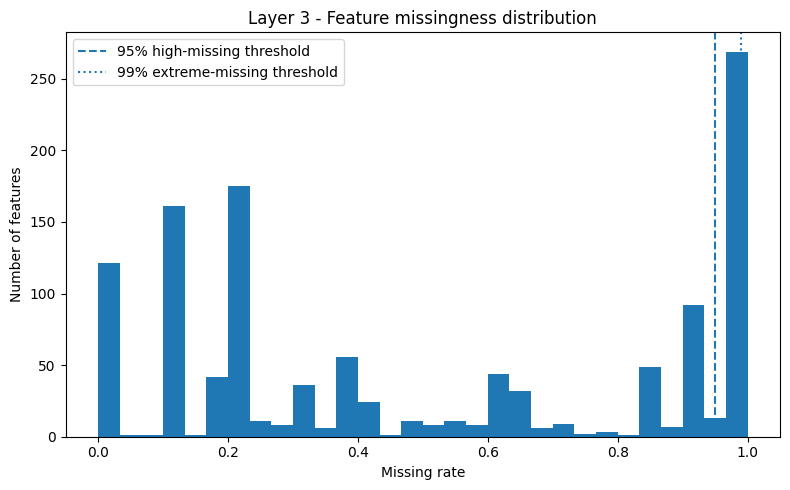

In [ ]:
# ============================================================
# Evidence A — Coverage checkpoint + diagnostics
# Legacy filename layer3_* is retained for downstream compatibility.
# ============================================================

coverage_evidence.to_csv(
    REPORT_ROOT
    / "layer3_coverage_evidence.csv",
    index=False,
)

coverage_summary = (
    coverage_evidence
    .groupby(
        "missing_band",
        as_index=False,
    )
    .agg(
        feature_count=(
            "feature",
            "count",
        ),
        median_missing_rate=(
            "missing_rate",
            "median",
        ),
        nzv_count=(
            "nzv_flag",
            "sum",
        ),
    )
    .sort_values(
        "feature_count",
        ascending=False,
    )
)

print(
    "Layer 3 summary："
)

display(
    coverage_summary
)

print(
    "Top missingness features："
)

display(
    coverage_evidence[
        [
            "feature",
            "missing_rate",
            "valid_count",
            "sample_percent_unique",
            "sample_dominant_share",
            "sample_frequency_ratio",
            "nzv_flag",
            "missing_band",
        ]
    ]
    .head(20)
)

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    coverage_evidence[
        "missing_rate"
    ].dropna(),
    bins=30,
)

plt.axvline(
    HIGH_MISSING_RATE,
    linestyle="--",
    label="95% high-missing threshold",
)

plt.axvline(
    EXTREME_MISSING_RATE,
    linestyle=":",
    label="99% extreme-missing threshold",
)

plt.xlabel(
    "Missing rate"
)

plt.ylabel(
    "Number of features"
)

plt.title(
    "Layer 3 - Feature missingness distribution"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_ROOT
    / "layer3_missingness_distribution.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

## 4. Evidence B — Univariate Relevance

这一模块问：

> **不考虑其他 features 时，X 自己和 target 有多少关系？**

这里保留两个不同的 Atomic Evidence：

```text
IV / IV percentile
MI / MI percentile
```

它们不是同一个量，也不应该因为最后有一个 `relevance_score` 就被理解成同一类证据。

### 4.1 IV：经过 grouping 以后，不同区域的 Good / Bad 分离程度

IV 建立在 WOE / grouped Good-Bad distribution 上，在 credit-risk 场景中很容易解释。

但 IV 会受到：

- numeric binning；
- categorical grouping；
- smoothing；

这些人为设定影响。

所以 `IV_MAX_CATEGORIES=20` 等参数属于真正值得审查的 **Evidence-construction parameters**。

既有的 Sensitivity Audit 已经设计了：

```text
20 / 40 / 100 categories
```

重点不是问 IV 从 0.12 变 0.15 是否“显著”，而是问：

> **IV ranking、后面的 Relevance ranking、Top-k membership 是否因此明显换人？**

### 4.2 MI：更一般的 statistical dependence evidence

MI 避免求关系是线性的，也不依赖同一套 WOE grouping。

连续变量的 MI 使用 kNN estimator，因此 sample size 本身可能影响估计。

当前预留：

```text
50k / 100k / 200k
```

的 sample-size audit，但只需要审查少量代表性 features，而不是把 1209 个 features 全部重算三遍。

### 4.3 为什么仍然保存 `relevance_score`？

当前 `relevance_score` 是 IV percentile 和 MI percentile 的等权参考组合。

它的作用是：

> **提供一个方便查看和下游兼容的 reference view。**

它不是理论上唯一正确的 Relevance 定义。

Notebook 9 更重要的任务，是直接读取：

```text
iv_percentile
mi_percentile
```

检查 IV-only、MI-only 和 reference / consensus ranking 有多一致。

如果它们几乎一样，就没有必要为了 0.4/0.6、0.3/0.7 再制造很多昂贵下游 routes。

如果它们明显不同，才说明 Relevance 本身存在值得保留的 ranking uncertainty。

### 4.4 为什么这里不声称是 CMIM / JMI？

这里计算的是单变量 MI(X;Y)。

Spearman、redundancy graph 或 tree-path clue 都不能因为和“条件关系”有关，就改名成 Conditional Mutual Information。

如果以后使用 CMIM / JMI，应当新增真正的 conditional / joint MI computation，而不是把现有 Evidence 重新命名。

**方法参考：** credit scoring 中的 WOE / IV；Mutual Information feature selection；Brown et al. (2012) 对信息论 feature-selection criteria 的统一讨论。


In [ ]:
from sklearn.feature_selection import (
    mutual_info_classif,
)


def learn_group_rule(
    series,
    dtype_family,
    max_numeric_bins=10,
    max_categories=20,
):
    """
    只根据 X 学 grouping。
    Numeric：sample quantiles。
    Categorical：sample 中最常见 levels。
    """

    if dtype_family == "numeric":

        non_missing = (
            pd.to_numeric(
                series,
                errors="coerce",
            )
            .dropna()
        )

        if (
            len(non_missing) == 0
            or
            non_missing.nunique()
            <= 1
        ):
            return {
                "type": "constant",
            }

        quantiles = np.linspace(
            0.0,
            1.0,
            max_numeric_bins + 1,
        )

        edges = np.unique(
            non_missing.quantile(
                quantiles
            )
            .to_numpy(
                dtype=float
            )
        )

        if len(edges) < 2:
            return {
                "type": "constant",
            }

        edges[0] = -np.inf
        edges[-1] = np.inf

        return {
            "type": "numeric",
            "edges": edges,
        }

    values = (
        series
        .astype("string")
        .fillna(
            MISSING_TOKEN
        )
    )

    levels = (
        values
        .value_counts()
        .head(
            max_categories
        )
        .index
        .astype(str)
        .tolist()
    )

    return {
        "type": "categorical",
        "levels": levels,
    }


def apply_group_rule(
    series,
    rule,
):
    """把已经冻结的 grouping rule 应用到新数据。"""

    if rule["type"] == "constant":

        return pd.Series(
            "__CONSTANT__",
            index=series.index,
            dtype="string",
        )

    if rule["type"] == "numeric":

        output = pd.cut(
            pd.to_numeric(
                series,
                errors="coerce",
            ),
            bins=rule["edges"],
            include_lowest=True,
            duplicates="drop",
        )

        return (
            output
            .astype("string")
            .fillna(
                MISSING_TOKEN
            )
        )

    values = (
        series
        .astype("string")
        .fillna(
            MISSING_TOKEN
        )
    )

    return values.where(
        values.isin(
            rule["levels"]
        ),
        "__OTHER__",
    )


def update_binary_count_dict(
    accumulator,
    groups,
    target,
):
    """把当前 batch 的 Good / Bad counts 加进 accumulator。"""

    table = pd.crosstab(
        groups,
        target,
    )

    for group_name, row in (
        table.iterrows()
    ):

        key = str(
            group_name
        )

        current = (
            accumulator
            .setdefault(
                key,
                [0, 0],
            )
        )

        current[0] += int(
            row.get(
                0,
                0,
            )
        )

        current[1] += int(
            row.get(
                1,
                0,
            )
        )


def count_dict_to_woe_table(
    count_dict,
):
    """由 full-data Good / Bad counts 计算 WOE / IV。"""

    groups = list(
        count_dict.keys()
    )

    good_raw = np.array(
        [
            count_dict[
                group
            ][0]
            for group in groups
        ],
        dtype=float,
    )

    bad_raw = np.array(
        [
            count_dict[
                group
            ][1]
            for group in groups
        ],
        dtype=float,
    )

    if len(groups) == 0:
        return pd.DataFrame(
            columns=[
                "group",
                "good_count",
                "bad_count",
                "woe",
                "iv_component",
            ]
        )

    good = (
        good_raw
        + IV_SMOOTHING
    )

    bad = (
        bad_raw
        + IV_SMOOTHING
    )

    good_dist = (
        good
        / good.sum()
    )

    bad_dist = (
        bad
        / bad.sum()
    )

    woe = np.log(
        good_dist
        / bad_dist
    )

    iv_component = (
        good_dist
        - bad_dist
    ) * woe

    return pd.DataFrame({
        "group": groups,
        "good_count": (
            good_raw.astype(
                np.int64
            )
        ),
        "bad_count": (
            bad_raw.astype(
                np.int64
            )
        ),
        "woe": woe,
        "iv_component": (
            iv_component
        ),
    })


# ------------------------------------------------------------
# 4A. sample 只用于学习 IV grouping rules
# ------------------------------------------------------------

iv_rule_positions = (
    make_stratified_positions(
        train_meta,
        IV_RULE_SAMPLE_SIZE,
        RANDOM_SEED + 10,
    )
)

dtype_family_lookup = (
    candidate_catalog
    .set_index("column")[
        "dtype_family"
    ]
    .to_dict()
)

iv_group_rules = {}


for start in range(
    0,
    len(candidate_features),
    IV_FEATURE_BATCH,
):

    batch_features = (
        candidate_features[
            start:
            start
            + IV_FEATURE_BATCH
        ]
    )

    sample_frame = (
        read_sampled_columns(
            batch_features,
            iv_rule_positions,
        )
    )

    for feature in batch_features:

        iv_group_rules[
            feature
        ] = learn_group_rule(
            sample_frame[
                feature
            ],
            dtype_family=(
                dtype_family_lookup[
                    feature
                ]
            ),
            max_numeric_bins=(
                IV_NUMERIC_BINS
            ),
            max_categories=(
                IV_MAX_CATEGORIES
            ),
        )

    del sample_frame
    gc.collect()

    print(
        "IV grouping rules：",
        min(
            start
            + IV_FEATURE_BATCH,
            len(candidate_features),
        ),
        "/",
        len(candidate_features),
    )


# ------------------------------------------------------------
# 4B. 最终 IV：完整 Train 上流式累计 Good / Bad
# ------------------------------------------------------------

iv_rows = []


for start in range(
    0,
    len(candidate_features),
    IV_FEATURE_BATCH,
):

    batch_features = (
        candidate_features[
            start:
            start
            + IV_FEATURE_BATCH
        ]
    )

    accumulators = {
        feature: {}
        for feature in batch_features
    }

    for row_group_id in range(
        train_parquet.num_row_groups
    ):

        frame = (
            train_parquet
            .read_row_group(
                row_group_id,
                columns=[
                    TARGET_COL,
                    *batch_features,
                ],
                use_threads=True,
            )
            .to_pandas()
        )

        y_batch = (
            frame[
                TARGET_COL
            ]
        )

        for feature in batch_features:

            groups = (
                apply_group_rule(
                    frame[
                        feature
                    ],
                    iv_group_rules[
                        feature
                    ],
                )
            )

            update_binary_count_dict(
                accumulators[
                    feature
                ],
                groups,
                y_batch,
            )

        del frame
        gc.collect()

    for feature in batch_features:

        woe_table = (
            count_dict_to_woe_table(
                accumulators[
                    feature
                ]
            )
        )

        iv_rows.append({
            "feature": feature,
            "iv": float(
                woe_table[
                    "iv_component"
                ].sum()
            ),
        })

    del accumulators
    gc.collect()

    print(
        "Full-data IV completed：",
        min(
            start
            + IV_FEATURE_BATCH,
            len(candidate_features),
        ),
        "/",
        len(candidate_features),
    )


iv_evidence = pd.DataFrame(
    iv_rows
)


# ------------------------------------------------------------
# 4C. MI：Week + target 分层 sample
# ------------------------------------------------------------

mi_positions = (
    make_stratified_positions(
        train_meta,
        MI_SAMPLE_SIZE,
        RANDOM_SEED + 20,
    )
)

y_mi = (
    train_meta
    .loc[
        mi_positions,
        TARGET_COL,
    ]
    .to_numpy(
        dtype=np.int8
    )
)

mi_rows = []


for start in range(
    0,
    len(numeric_features),
    MI_FEATURE_BATCH,
):

    batch_features = (
        numeric_features[
            start:
            start
            + MI_FEATURE_BATCH
        ]
    )

    batch = (
        read_sampled_columns(
            batch_features,
            mi_positions,
        )
    )

    usable_features = []
    matrix_parts = []

    for feature in batch_features:

        values = pd.to_numeric(
            batch[
                feature
            ],
            errors="coerce",
        )

        median_value = (
            values.median()
        )

        if pd.isna(
            median_value
        ):
            continue

        usable_features.append(
            feature
        )

        matrix_parts.append(
            values
            .fillna(
                median_value
            )
            .to_numpy(
                dtype=np.float32
            )
        )

    if matrix_parts:

        matrix = np.column_stack(
            matrix_parts
        )

        mi_values = (
            mutual_info_classif(
                matrix,
                y_mi,
                discrete_features=False,
                random_state=(
                    RANDOM_SEED
                ),
                n_neighbors=3,
            )
        )

        for feature, value in zip(
            usable_features,
            mi_values,
        ):

            mi_rows.append({
                "feature": feature,
                "mi": float(value),
            })

        del matrix

    del (
        batch,
        matrix_parts,
    )

    gc.collect()

    print(
        "MI numerical completed：",
        min(
            start
            + MI_FEATURE_BATCH,
            len(numeric_features),
        ),
        "/",
        len(numeric_features),
    )


for start in range(
    0,
    len(categorical_features),
    MI_FEATURE_BATCH,
):

    batch_features = (
        categorical_features[
            start:
            start
            + MI_FEATURE_BATCH
        ]
    )

    batch = (
        read_sampled_columns(
            batch_features,
            mi_positions,
        )
    )

    matrix_parts = []

    for feature in batch_features:

        values = (
            batch[
                feature
            ]
            .astype("string")
            .fillna(
                MISSING_TOKEN
            )
        )

        codes, _ = pd.factorize(
            values,
            sort=False,
        )

        matrix_parts.append(
            codes.astype(
                np.int32
            )
        )

    if matrix_parts:

        matrix = np.column_stack(
            matrix_parts
        )

        mi_values = (
            mutual_info_classif(
                matrix,
                y_mi,
                discrete_features=True,
                random_state=(
                    RANDOM_SEED
                ),
            )
        )

        for feature, value in zip(
            batch_features,
            mi_values,
        ):

            mi_rows.append({
                "feature": feature,
                "mi": float(value),
            })

        del matrix

    del (
        batch,
        matrix_parts,
    )

    gc.collect()


mi_evidence = pd.DataFrame(
    mi_rows
)


relevance_evidence = (
    candidate_catalog[
        [
            "column",
            "dtype_family",
            "origin",
        ]
    ]
    .rename(
        columns={
            "column": "feature"
        }
    )
    .merge(
        iv_evidence,
        on="feature",
        how="left",
    )
    .merge(
        mi_evidence,
        on="feature",
        how="left",
    )
)


relevance_evidence[
    "iv_percentile"
] = (
    relevance_evidence[
        "iv"
    ]
    .rank(
        pct=True,
        method="average",
    )
)

relevance_evidence[
    "mi_percentile"
] = (
    relevance_evidence[
        "mi"
    ]
    .rank(
        pct=True,
        method="average",
    )
)

relevance_evidence[
    "relevance_score"
] = (
    relevance_evidence[
        [
            "iv_percentile",
            "mi_percentile",
        ]
    ]
    .mean(axis=1)
)


relevance_evidence = (
    relevance_evidence
    .sort_values(
        "relevance_score",
        ascending=False,
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Optional MI sample-size audit
# ------------------------------------------------------------

mi_sample_audit = pd.DataFrame()


def compute_mi_for_selected_features(
    features,
    positions,
):
    """只对少量 features 重算 MI，用于 sample-size audit。"""

    rows = []

    y = (
        train_meta
        .loc[
            positions,
            TARGET_COL,
        ]
        .to_numpy(
            dtype=np.int8
        )
    )

    for feature in features:

        frame = read_sampled_columns(
            [feature],
            positions,
        )

        family = (
            dtype_family_lookup[
                feature
            ]
        )

        if family == "numeric":

            values = pd.to_numeric(
                frame[
                    feature
                ],
                errors="coerce",
            )

            median_value = (
                values.median()
            )

            if pd.isna(
                median_value
            ):
                value = np.nan
            else:
                matrix = (
                    values
                    .fillna(
                        median_value
                    )
                    .to_numpy(
                        dtype=np.float32
                    )
                    .reshape(-1, 1)
                )

                value = float(
                    mutual_info_classif(
                        matrix,
                        y,
                        discrete_features=False,
                        random_state=(
                            RANDOM_SEED
                        ),
                        n_neighbors=3,
                    )[0]
                )

        else:

            values = (
                frame[
                    feature
                ]
                .astype("string")
                .fillna(
                    MISSING_TOKEN
                )
            )

            codes, _ = pd.factorize(
                values,
                sort=False,
            )

            value = float(
                mutual_info_classif(
                    codes.reshape(
                        -1,
                        1,
                    ),
                    y,
                    discrete_features=True,
                    random_state=(
                        RANDOM_SEED
                    ),
                )[0]
            )

        rows.append({
            "feature": feature,
            "mi": value,
        })

        del frame
        gc.collect()

    return pd.DataFrame(
        rows
    )


if RUN_MI_SAMPLE_AUDIT:

    top_features = (
        relevance_evidence
        .sort_values(
            "mi",
            ascending=False,
        )
        .head(
            MI_AUDIT_FEATURE_COUNT
        )[
            "feature"
        ]
        .tolist()
    )

    audit_parts = []

    for sample_size in (
        MI_AUDIT_SIZES
    ):

        positions = (
            make_stratified_positions(
                train_meta,
                sample_size,
                RANDOM_SEED + 100
                + sample_size,
            )
        )

        result = (
            compute_mi_for_selected_features(
                top_features,
                positions,
            )
        )

        result[
            "sample_size"
        ] = sample_size

        audit_parts.append(
            result
        )

    mi_sample_audit = pd.concat(
        audit_parts,
        ignore_index=True,
    )

    audit_pivot = (
        mi_sample_audit
        .pivot(
            index="feature",
            columns="sample_size",
            values="mi",
        )
    )

    print(
        "MI sample-size audit "
        "Spearman correlations："
    )

    display(
        audit_pivot.corr(
            method="spearman"
        )
    )


display(
    relevance_evidence.head(30)
)

IV grouping rules： 24 / 1209
IV grouping rules： 48 / 1209
IV grouping rules： 72 / 1209
IV grouping rules： 96 / 1209
IV grouping rules： 120 / 1209
IV grouping rules： 144 / 1209
IV grouping rules： 168 / 1209
IV grouping rules： 192 / 1209
IV grouping rules： 216 / 1209
IV grouping rules： 240 / 1209
IV grouping rules： 264 / 1209
IV grouping rules： 288 / 1209
IV grouping rules： 312 / 1209
IV grouping rules： 336 / 1209
IV grouping rules： 360 / 1209
IV grouping rules： 384 / 1209
IV grouping rules： 408 / 1209
IV grouping rules： 432 / 1209
IV grouping rules： 456 / 1209
IV grouping rules： 480 / 1209
IV grouping rules： 504 / 1209
IV grouping rules： 528 / 1209
IV grouping rules： 552 / 1209
IV grouping rules： 576 / 1209
IV grouping rules： 600 / 1209
IV grouping rules： 624 / 1209
IV grouping rules： 648 / 1209
IV grouping rules： 672 / 1209
IV grouping rules： 696 / 1209
IV grouping rules： 720 / 1209
IV grouping rules： 744 / 1209
IV grouping rules： 768 / 1209
IV grouping rules： 792 / 1209
IV grouping ru

,feature,dtype_family,origin,iv,mi,iv_percentile,mi_percentile,relevance_score
0,datelastinstal40dpd_247D__days_before_decision,numeric,derived_from_date,0.163630,0.017476,0.948718,0.848635,0.898677
1,pmtcount_693L,numeric,original,0.046773,0.023497,0.830438,0.938792,0.884615
2,overdueamountmax2date_1142D_min__days_before_d...,numeric,derived_from_date,0.159134,0.013778,0.946237,0.780811,0.863524
3,assignmentdate_238D__days_before_decision,numeric,derived_from_date,0.049935,0.019439,0.849462,0.874276,0.861869
4,numberofoverdueinstlmaxdat_641D_max__days_befo...,numeric,derived_from_date,0.192171,0.010028,0.962779,0.754342,0.858561
5,overdueamountmax2date_1142D_max__days_before_d...,numeric,derived_from_date,0.178567,0.010469,0.953681,0.758478,0.856079
6,dpdmaxdateyear_596T_max,numeric,original,0.132801,0.012165,0.934657,0.770885,0.852771
7,lastdelinqdate_224D__days_before_decision,numeric,derived_from_date,0.150312,0.009545,0.941274,0.751034,0.846154
8,dpdmaxdateyear_896T_max,numeric,original,0.105670,0.011994,0.923077,0.768404,0.845740
9,numberofoverdueinstlmaxdat_641D_min__days_befo...,numeric,derived_from_date,0.172274,0.008735,0.951199,0.739454,0.845327


Top univariate evidence：


,feature,dtype_family,iv,mi,iv_percentile,mi_percentile,relevance_score
0,datelastinstal40dpd_247D__days_before_decision,numeric,0.163630,0.017476,0.948718,0.848635,0.898677
1,pmtcount_693L,numeric,0.046773,0.023497,0.830438,0.938792,0.884615
2,overdueamountmax2date_1142D_min__days_before_d...,numeric,0.159134,0.013778,0.946237,0.780811,0.863524
3,assignmentdate_238D__days_before_decision,numeric,0.049935,0.019439,0.849462,0.874276,0.861869
4,numberofoverdueinstlmaxdat_641D_max__days_befo...,numeric,0.192171,0.010028,0.962779,0.754342,0.858561
5,overdueamountmax2date_1142D_max__days_before_d...,numeric,0.178567,0.010469,0.953681,0.758478,0.856079
6,dpdmaxdateyear_596T_max,numeric,0.132801,0.012165,0.934657,0.770885,0.852771
7,lastdelinqdate_224D__days_before_decision,numeric,0.150312,0.009545,0.941274,0.751034,0.846154
8,dpdmaxdateyear_896T_max,numeric,0.105670,0.011994,0.923077,0.768404,0.845740
9,numberofoverdueinstlmaxdat_641D_min__days_befo...,numeric,0.172274,0.008735,0.951199,0.739454,0.845327


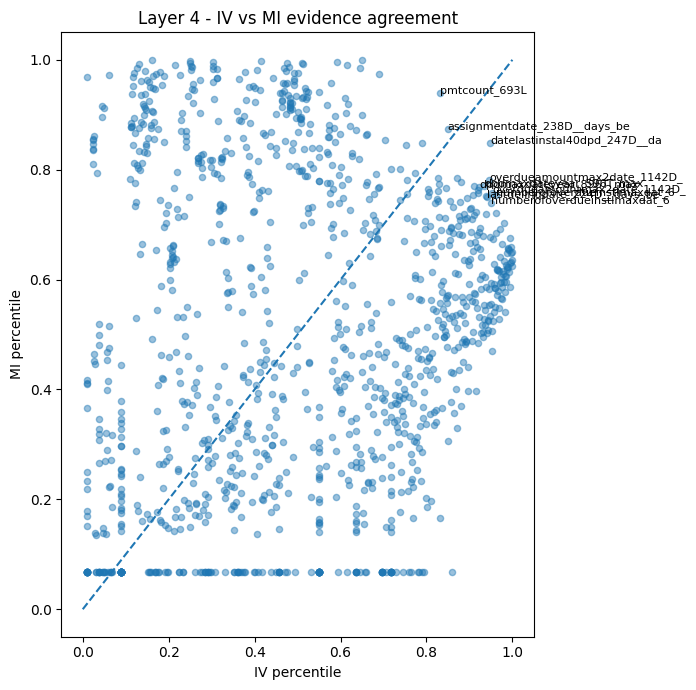

In [ ]:
# ============================================================
# Evidence B — Univariate Relevance checkpoint + diagnostics
# Legacy filename layer4_* is retained for downstream compatibility.
# ============================================================

relevance_evidence.to_csv(
    REPORT_ROOT
    / "layer4_relevance_evidence.csv",
    index=False,
)

if not mi_sample_audit.empty:

    mi_sample_audit.to_csv(
        REPORT_ROOT
        / "layer4_mi_sample_size_audit.csv",
        index=False,
    )

print(
    "Top univariate evidence："
)

display(
    relevance_evidence[
        [
            "feature",
            "dtype_family",
            "iv",
            "mi",
            "iv_percentile",
            "mi_percentile",
            "relevance_score",
        ]
    ]
    .head(25)
)

# 用 percentile 比较 IV 与 MI，避免 raw scale 不同造成视觉误导。
plot_data = (
    relevance_evidence
    .dropna(
        subset=[
            "iv_percentile",
            "mi_percentile",
        ]
    )
    .copy()
)

plt.figure(
    figsize=(7, 7)
)

plt.scatter(
    plot_data[
        "iv_percentile"
    ],
    plot_data[
        "mi_percentile"
    ],
    alpha=0.45,
    s=20,
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

annotate_rows = (
    plot_data
    .sort_values(
        "relevance_score",
        ascending=False,
    )
    .head(10)
)

for row in (
    annotate_rows
    .itertuples(
        index=False
    )
):

    plt.annotate(
        row.feature[:28],
        (
            row.iv_percentile,
            row.mi_percentile,
        ),
        fontsize=8,
    )

plt.xlabel(
    "IV percentile"
)

plt.ylabel(
    "MI percentile"
)

plt.title(
    "Layer 4 - IV vs MI evidence agreement"
)

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT
    / "layer4_iv_vs_mi_percentile.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

## 5. Evidence C — Redundancy & Substitutability

这一模块问：

> **两个 features 是否可能在提供非常相似的信息？**

不同数据类型使用不同关系指标：

- Numerical ↔ Numerical：Spearman；
- Categorical ↔ Categorical：Cramér's V；
- Numerical ↔ Categorical：Correlation Ratio / eta²。

这里不把三种统计量强行加成一个 RedundancyScore，因为它们本来就在不同 feature-type space 中回答不同问题。

### 为什么只建立 redundancy relation，而不直接删除？

假设 A 和 B 高度相关。

这并不能证明：

```text
A 一定保留
B 一定删除
```

因为它们还可能在：

- temporal stability；
- missing pattern；
- interaction；
- model contribution

上表现不同。

所以 Notebook 8 只保存：

> **谁和谁可能互相替代。**

Notebook 9 的 redundancy-aware ranking 再利用这些关系改变 priority。

### 成本为什么这样分配？

所有 numerical pairs、categorical pairs、mixed pairs 全部高精度计算会快速膨胀。

因此这里对高成本 mixed-type relation 使用 targeted review，并对 pairwise correlation 使用固定 sample。

减少的成本针对的是：

> **pairwise state explosion。**

但并未把 redundancy 本身删除掉，因为如果完全忽略 redundancy，后面的 Top-k 可能被大量相似 features 占满。

### Sensitivity 副线

0.85、0.80 这类 threshold 暂时不做大规模 grid。

更合理的顺序是先看：

> **有多少 pair 正好集中在 threshold 附近？**

只有 boundary mass 很大，而且 threshold 会明显改变 redundancy graph 时，才值得支付进一步 sensitivity cost。


In [ ]:
from scipy.cluster import (
    hierarchy,
)
from scipy.spatial.distance import (
    squareform,
)


redundancy_positions = (
    make_stratified_positions(
        train_meta,
        REDUNDANCY_SAMPLE_SIZE,
        RANDOM_SEED + 30,
    )
)


# ------------------------------
# Numerical ↔ Numerical
# ------------------------------

numeric_sample = (
    read_sampled_columns_blockwise(
        numeric_features,
        redundancy_positions,
        column_batch_size=(
            SAMPLED_READ_FEATURE_BATCH
        ),
    )
)

for feature in numeric_features:
    numeric_sample[
        feature
    ] = pd.to_numeric(
        numeric_sample[
            feature
        ],
        errors="coerce",
    ).astype(
        np.float32
    )


numeric_corr = (
    numeric_sample
    .corr(
        method="spearman",
    )
    .fillna(0.0)
)

del numeric_sample
gc.collect()


np.fill_diagonal(
    numeric_corr.values,
    1.0,
)

numeric_distance = (
    1.0
    - numeric_corr.abs()
)

numeric_distance = (
    numeric_distance
    .clip(
        lower=0.0,
        upper=1.0,
    )
)

condensed_distance = squareform(
    numeric_distance.to_numpy(),
    checks=False,
)

numeric_linkage = hierarchy.linkage(
    condensed_distance,
    method="average",
)

numeric_cluster_ids = (
    hierarchy.fcluster(
        numeric_linkage,
        t=(
            1.0
            - NUMERIC_REDUNDANCY_RHO
        ),
        criterion="distance",
    )
)

numeric_redundancy = pd.DataFrame({
    "feature": numeric_features,
    "numeric_redundancy_group": (
        numeric_cluster_ids
    ),
})


numeric_redundancy[
    "numeric_cluster_size"
] = (
    numeric_redundancy
    .groupby(
        "numeric_redundancy_group"
    )[
        "feature"
    ]
    .transform("size")
)


# ------------------------------
# Categorical ↔ Categorical
# ------------------------------

def corrected_cramers_v(
    x,
    y,
):
    """Bias-corrected Cramér's V。"""

    table = pd.crosstab(
        x,
        y,
    )

    if (
        table.shape[0] < 2
        or
        table.shape[1] < 2
    ):
        return 0.0

    observed = table.to_numpy(
        dtype=float
    )

    n = observed.sum()

    if n <= 1:
        return 0.0

    row_sum = observed.sum(
        axis=1,
        keepdims=True,
    )

    col_sum = observed.sum(
        axis=0,
        keepdims=True,
    )

    expected = (
        row_sum
        @ col_sum
        / n
    )

    valid = expected > 0

    chi2 = (
        (
            (observed - expected) ** 2
            / np.where(
                valid,
                expected,
                1.0,
            )
        )[valid]
        .sum()
    )

    phi2 = chi2 / n

    r, k = observed.shape

    phi2_corr = max(
        0.0,
        phi2
        - (
            (k - 1)
            * (r - 1)
            / max(
                n - 1,
                1,
            )
        ),
    )

    r_corr = (
        r
        - (
            (r - 1) ** 2
            / max(
                n - 1,
                1,
            )
        )
    )

    k_corr = (
        k
        - (
            (k - 1) ** 2
            / max(
                n - 1,
                1,
            )
        )
    )

    denominator = min(
        k_corr - 1,
        r_corr - 1,
    )

    if denominator <= 0:
        return 0.0

    return float(
        np.sqrt(
            phi2_corr
            / denominator
        )
    )


categorical_sample = (
    read_sampled_columns_blockwise(
        categorical_features,
        redundancy_positions,
        column_batch_size=(
            SAMPLED_READ_FEATURE_BATCH
        ),
    )
)


categorical_pair_rows = []

for feature_a, feature_b in combinations(
    categorical_features,
    2,
):

    x = (
        categorical_sample[
            feature_a
        ]
        .astype("string")
        .fillna(
            MISSING_TOKEN
        )
    )

    y = (
        categorical_sample[
            feature_b
        ]
        .astype("string")
        .fillna(
            MISSING_TOKEN
        )
    )

    v = corrected_cramers_v(
        x,
        y,
    )

    if v >= (
        CATEGORICAL_REDUNDANCY_V
    ):

        categorical_pair_rows.append({
            "feature_a": feature_a,
            "feature_b": feature_b,
            "cramers_v": v,
        })


categorical_redundancy_pairs = (
    pd.DataFrame(
        categorical_pair_rows,
        columns=[
            "feature_a",
            "feature_b",
            "cramers_v",
        ],
    )
)

if not categorical_redundancy_pairs.empty:
    categorical_redundancy_pairs = (
        categorical_redundancy_pairs
        .sort_values(
            "cramers_v",
            ascending=False,
        )
        .reset_index(drop=True)
    )


display(
    numeric_redundancy
    .loc[
        numeric_redundancy[
            "numeric_cluster_size"
        ].gt(1)
    ]
    .sort_values(
        [
            "numeric_cluster_size",
            "numeric_redundancy_group",
        ],
        ascending=[False, True],
    )
    .head(30)
)

display(
    categorical_redundancy_pairs.head(
        30
    )
)

Sample columns loaded： 64 / 1150
Sample columns loaded： 128 / 1150
Sample columns loaded： 192 / 1150
Sample columns loaded： 256 / 1150
Sample columns loaded： 320 / 1150
Sample columns loaded： 384 / 1150
Sample columns loaded： 448 / 1150
Sample columns loaded： 512 / 1150
Sample columns loaded： 576 / 1150
Sample columns loaded： 640 / 1150
Sample columns loaded： 704 / 1150
Sample columns loaded： 768 / 1150
Sample columns loaded： 832 / 1150
Sample columns loaded： 896 / 1150
Sample columns loaded： 960 / 1150
Sample columns loaded： 1024 / 1150
Sample columns loaded： 1088 / 1150
Sample columns loaded： 1150 / 1150
Sample columns loaded： 59 / 59


,feature,numeric_redundancy_group,numeric_cluster_size
427,numberofoverdueinstlmax_1039L_max,87,35
428,numberofoverdueinstlmax_1039L_mean,87,35
429,numberofoverdueinstlmax_1039L_sum,87,35
539,dpdmax_139P_max,87,35
540,dpdmax_139P_mean,87,35
541,dpdmax_139P_sum,87,35
543,overdueamountmax2_14A_max,87,35
544,overdueamountmax2_14A_mean,87,35
545,overdueamountmax2_14A_sum,87,35
555,overdueamountmax_155A_max,87,35


,feature_a,feature_b,cramers_v
0,person_related4_role_1084L,person_related4_type_25L,1.000000
1,isbidproductrequest_292L,person_main_gender_992L,0.999987
2,person_related4_relationshiptoclient_642T,person_related4_role_1084L,0.999887
3,person_related4_relationshiptoclient_642T,person_related4_type_25L,0.999887
4,disbursementtype_67L,inittransactioncode_186L,0.999008
5,lastst_736L,last_status_219L,0.984982
6,person_main_contaddr_zipcode_807M,person_main_registaddr_zipcode_184M,0.978204
7,person_main_contaddr_district_15M,person_main_registaddr_district_1083M,0.975213
8,person_related3_role_1084L,person_related3_type_25L,0.973155
9,person_main_role_1084L,person_related1_type_25L,0.962305


In [ ]:
# ------------------------------
# Numerical ↔ Categorical
# targeted review
# ------------------------------

def correlation_ratio_eta2(
    numeric,
    categorical,
):
    """Categorical 对 numerical 均值结构的 eta²。"""

    frame = pd.DataFrame({
        "numeric": numeric,
        "category": (
            categorical
            .astype("string")
            .fillna(
                MISSING_TOKEN
            )
        ),
    }).dropna(
        subset=["numeric"]
    )

    if len(frame) == 0:
        return np.nan

    overall_mean = (
        frame[
            "numeric"
        ].mean()
    )

    total_ss = (
        (
            frame[
                "numeric"
            ]
            - overall_mean
        ) ** 2
    ).sum()

    if total_ss <= 0:
        return 0.0

    between_ss = 0.0

    for _, group in frame.groupby(
        "category",
        observed=True,
    ):

        between_ss += (
            len(group)
            * (
                group[
                    "numeric"
                ].mean()
                - overall_mean
            ) ** 2
        )

    return float(
        between_ss
        / total_ss
    )


top_numeric = (
    relevance_evidence
    .loc[
        relevance_evidence[
            "dtype_family"
        ].eq("numeric")
    ]
    .head(
        MIXED_TOP_NUMERIC
    )[
        "feature"
    ]
    .tolist()
)

top_categorical = (
    relevance_evidence
    .loc[
        relevance_evidence[
            "dtype_family"
        ].isin(
            [
                "categorical",
                "boolean",
            ]
        )
    ]
    .head(
        MIXED_TOP_CATEGORICAL
    )[
        "feature"
    ]
    .tolist()
)

origin_lookup = (
    candidate_catalog
    .set_index("column")[
        "origin"
    ]
    .to_dict()
)


mixed_features_to_read = list(
    dict.fromkeys([
        *top_numeric,
        *top_categorical,
    ])
)

mixed_sample = (
    read_sampled_columns_blockwise(
        mixed_features_to_read,
        redundancy_positions,
        column_batch_size=(
            SAMPLED_READ_FEATURE_BATCH
        ),
    )
)


mixed_rows = []

for numeric_feature in top_numeric:

    for categorical_feature in (
        top_categorical
    ):

        if (
            origin_lookup.get(
                numeric_feature
            )
            !=
            origin_lookup.get(
                categorical_feature
            )
        ):
            continue

        category_count = (
            mixed_sample[
                categorical_feature
            ]
            .nunique(
                dropna=False
            )
        )

        if category_count > (
            MIXED_MAX_CATEGORY_LEVELS
        ):
            continue

        eta2 = correlation_ratio_eta2(
            pd.to_numeric(
                mixed_sample[
                    numeric_feature
                ],
                errors="coerce",
            ),
            mixed_sample[
                categorical_feature
            ],
        )

        if (
            pd.notna(
                eta2
            )
            and
            eta2
            >= MIXED_ETA2_REVIEW
        ):

            mixed_rows.append({
                "numeric_feature": (
                    numeric_feature
                ),
                "categorical_feature": (
                    categorical_feature
                ),
                "eta2": eta2,
                "origin": (
                    origin_lookup.get(
                        numeric_feature
                    )
                ),
            })


mixed_redundancy_review = (
    pd.DataFrame(
        mixed_rows,
        columns=[
            "numeric_feature",
            "categorical_feature",
            "eta2",
            "origin",
        ],
    )
)

if not mixed_redundancy_review.empty:
    mixed_redundancy_review = (
        mixed_redundancy_review
        .sort_values(
            "eta2",
            ascending=False,
        )
        .reset_index(drop=True)
    )


del (
    categorical_sample,
    mixed_sample,
)

gc.collect()


# ------------------------------
# Optional sample-size audit
# ------------------------------

redundancy_sample_audit = (
    pd.DataFrame()
)


def high_corr_pairs_from_matrix(
    corr_matrix,
    threshold,
):
    """返回 |rho| >= threshold 的无重复 pair set。"""

    values = (
        corr_matrix
        .abs()
        .to_numpy()
    )

    names = list(
        corr_matrix.columns
    )

    rows, cols = np.where(
        np.triu(
            values,
            k=1,
        )
        >= threshold
    )

    return {
        (
            names[i],
            names[j],
        )
        for i, j in zip(
            rows,
            cols,
        )
    }


if RUN_REDUNDANCY_SAMPLE_AUDIT:

    audit_positions = (
        make_stratified_positions(
            train_meta,
            REDUNDANCY_AUDIT_SIZE,
            RANDOM_SEED + 31,
        )
    )

    audit_numeric = (
        read_sampled_columns_blockwise(
            numeric_features,
            audit_positions,
            column_batch_size=(
                SAMPLED_READ_FEATURE_BATCH
            ),
        )
    )

    for feature in numeric_features:
        audit_numeric[
            feature
        ] = pd.to_numeric(
            audit_numeric[
                feature
            ],
            errors="coerce",
        ).astype(
            np.float32
        )

    audit_corr = (
        audit_numeric
        .corr(
            method="spearman",
        )
        .fillna(0.0)
    )

    primary_pairs = (
        high_corr_pairs_from_matrix(
            numeric_corr,
            NUMERIC_REDUNDANCY_RHO,
        )
    )

    audit_pairs = (
        high_corr_pairs_from_matrix(
            audit_corr,
            NUMERIC_REDUNDANCY_RHO,
        )
    )

    union_pairs = (
        primary_pairs
        | audit_pairs
    )

    jaccard = (
        len(
            primary_pairs
            & audit_pairs
        )
        / len(union_pairs)
        if union_pairs
        else 1.0
    )

    redundancy_sample_audit = (
        pd.DataFrame([
            {
                "primary_sample_size": (
                    REDUNDANCY_SAMPLE_SIZE
                ),
                "audit_sample_size": (
                    REDUNDANCY_AUDIT_SIZE
                ),
                "primary_high_corr_pairs": (
                    len(primary_pairs)
                ),
                "audit_high_corr_pairs": (
                    len(audit_pairs)
                ),
                "pair_jaccard": (
                    jaccard
                ),
            }
        ])
    )

    display(
        redundancy_sample_audit
    )

    del (
        audit_numeric,
        audit_corr,
    )

    gc.collect()


display(
    mixed_redundancy_review.head(
        30
    )
)

Sample columns loaded： 64 / 130
Sample columns loaded： 128 / 130
Sample columns loaded： 130 / 130


,numeric_feature,categorical_feature,eta2,origin
0,riskassesment_940T,riskassesment_302T,0.90291,original


Largest numerical redundancy groups：


,numeric_redundancy_group,cluster_size,features
0,87,35,numberofoverdueinstlmax_1039L_max | numberofov...
1,420,34,person2_meaningful_detail_count_sum | person2_...
2,309,34,classificationofcontr_400M_nunique | financial...
3,275,31,financialinstitution_591M_nunique | numberofov...
4,86,21,numberofoverdueinstls_725L_max | numberofoverd...
5,88,19,overdueamountmax2_398A_max | overdueamountmax2...
6,179,19,annuitynextmonth_57A | currdebt_22A | numinstl...
7,354,16,applprev_n_records | actualdpd_943P_cnt | annu...
8,215,14,residualamount_856A_max | residualamount_856A_...
9,262,12,outstandingamount_362A_max | outstandingamount...


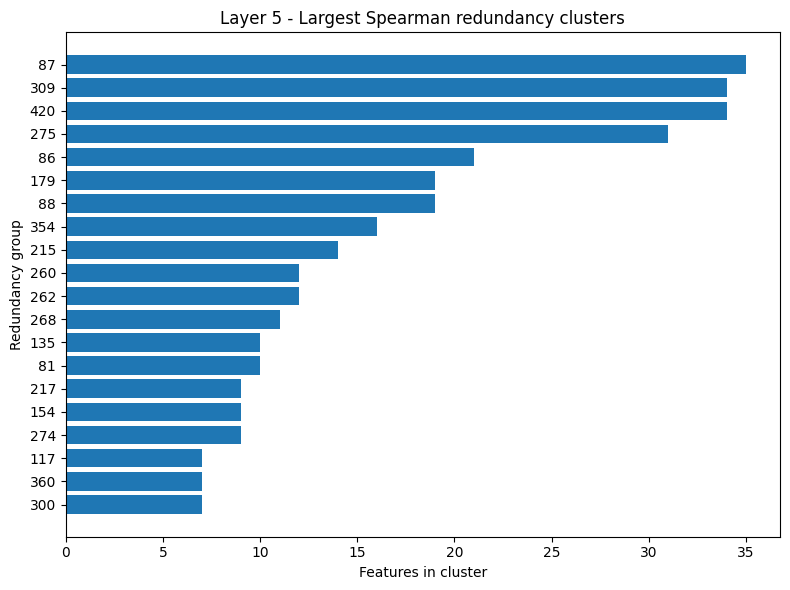

In [ ]:
# ============================================================
# Evidence C — Redundancy checkpoint + diagnostics
# Legacy filename layer5_* is retained for downstream compatibility.
# ============================================================

numeric_redundancy.to_csv(
    REPORT_ROOT
    / "layer5_numeric_redundancy_groups.csv",
    index=False,
)

categorical_redundancy_pairs.to_csv(
    REPORT_ROOT
    / "layer5_categorical_redundancy_pairs.csv",
    index=False,
)

mixed_redundancy_review.to_csv(
    REPORT_ROOT
    / "layer5_mixed_redundancy_review.csv",
    index=False,
)

cluster_summary = (
    numeric_redundancy
    .groupby(
        "numeric_redundancy_group",
        as_index=False,
    )
    .agg(
        cluster_size=(
            "feature",
            "size",
        ),
        features=(
            "feature",
            lambda values: " | ".join(
                list(values)[:6]
            ),
        ),
    )
    .loc[
        lambda frame:
        frame[
            "cluster_size"
        ].gt(1)
    ]
    .sort_values(
        "cluster_size",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)

print(
    "Largest numerical redundancy groups："
)

display(
    cluster_summary.head(20)
)

if not cluster_summary.empty:

    plot_clusters = (
        cluster_summary
        .head(20)
        .sort_values(
            "cluster_size",
            ascending=True,
        )
    )

    plt.figure(
        figsize=(8, 6)
    )

    plt.barh(
        plot_clusters[
            "numeric_redundancy_group"
        ].astype(str),
        plot_clusters[
            "cluster_size"
        ],
    )

    plt.xlabel(
        "Features in cluster"
    )

    plt.ylabel(
        "Redundancy group"
    )

    plt.title(
        "Layer 5 - Largest Spearman redundancy clusters"
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_ROOT
        / "layer5_redundancy_cluster_sizes.png",
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()

## 6. Evidence D — Model Contribution

Relevance 问的是：

> X 自己有没有信息？

这一模块进一步问：

> **X 放进一个多变量 learner 后，模型实际怎样使用它？**

这里保留两个不同证据：

### 6.1 Gain Importance

Gain 描述 LightGBM 在训练过程中使用某个 feature 做 split 时带来的目标函数改善。

它覆盖完整 candidate set，因此很适合作为 Tree branch 的完整 Model-Contribution ranking evidence。

### 6.2 Permutation Importance

Permutation 回答的是另一个问题：

> 在固定 assessment data 上，把 X 打乱以后，已经训练好的模型会坏多少？

它更接近 model reliance。

但高度相关 features 会互相替代，因此 permutation importance 可能因为 redundancy 被压低。

所以 Gain 和 Permutation 的分歧本身就是信息，而不是一定要被一个平均分抹平。

### 6.3 当前 `model_score` 应该怎样理解？

当前 notebook 仍然保存 Gain percentile 与 Permutation percentile 的等权 reference composite，主要为了诊断和兼容。

但它不是唯一的 Model Evidence。

尤其当前 Permutation 只对 Gain 前部候选做，所以 Notebook 9 不应该把 `model_score` 当成对全部 features 完全同定义的唯一排名。

更稳妥的解释是：

```text
Gain
→ 完整 Tree ranking evidence

Permutation
→ 对前部重要 features 的 assessment-side reliance audit
```

### 为什么值得增加这部分成本？

如果只看 IV / MI，就可能保留很多单独有信息、但进入多变量模型后几乎没有新增价值的 features。

因此训练一个 reference LightGBM 和做有限 permutation 是**必要成本**：它在防止“单变量证据被误当成多变量贡献”。

### 为什么又不能无限增加？

Permutation 对所有 1,209 个 features × 多次 repeats 的成本很高，而且大量尾部 features 很可能不会改变判断。

所以当前集中在前部候选，是在保留高信息价值 evaluation 的同时砍掉重复成本。

### Sensitivity 副线

`LGBM_BIN_SAMPLE_COUNT=50_000` 会影响 LightGBM 构造 histogram bins。

如果要审查它，合理方式不是跑三套完整 NB8，而是只训练少量：

```text
50k / 100k / 200k
```

reference models，比较 Gain ranking / Top-k overlap。

只有 Gain ranking 真正发生明显变化，才继续向下支付 Permutation / Interaction 等成本。


In [ ]:
import lightgbm as lgb
from sklearn.metrics import (
    roc_auc_score,
)


def learn_lgbm_category_rules(
    categorical_features,
    week_start,
    week_end,
):
    """
    只在 model-fit window 学 categorical levels。
    分 feature batch + row group 统计频数。
    """

    rules = {}

    normal_limit = max(
        1,
        LGBM_MAX_CATEGORIES - 2,
    )

    for start in range(
        0,
        len(categorical_features),
        CATEGORICAL_RULE_BATCH,
    ):

        batch_features = (
            categorical_features[
                start:
                start
                + CATEGORICAL_RULE_BATCH
            ]
        )

        counters = {
            feature: Counter()
            for feature in batch_features
        }

        for row_group_id in range(
            train_parquet.num_row_groups
        ):

            frame = (
                train_parquet
                .read_row_group(
                    row_group_id,
                    columns=[
                        WEEK_COL,
                        *batch_features,
                    ],
                    use_threads=True,
                )
                .to_pandas()
            )

            mask = (
                frame[
                    WEEK_COL
                ]
                .between(
                    week_start,
                    week_end,
                )
            )

            if mask.any():

                selected = (
                    frame.loc[
                        mask,
                        batch_features,
                    ]
                )

                for feature in (
                    batch_features
                ):

                    values = (
                        selected[
                            feature
                        ]
                        .astype(
                            "string"
                        )
                        .fillna(
                            MISSING_TOKEN
                        )
                    )

                    counts = (
                        values
                        .value_counts()
                    )

                    counters[
                        feature
                    ].update(
                        {
                            str(key): int(value)
                            for key, value
                            in counts.items()
                        }
                    )

            del frame
            gc.collect()

        for feature in batch_features:

            normal_counts = [
                (
                    category,
                    count,
                )
                for category, count
                in counters[
                    feature
                ].items()
                if category
                not in {
                    MISSING_TOKEN,
                    RARE_TOKEN,
                }
            ]

            normal_counts.sort(
                key=lambda item: (
                    -item[1],
                    item[0],
                )
            )

            kept_normal = [
                category
                for category, _
                in normal_counts[
                    :normal_limit
                ]
            ]

            categories = [
                *kept_normal,
                MISSING_TOKEN,
                RARE_TOKEN,
            ]

            rules[
                feature
            ] = {
                "categories": (
                    categories
                ),
                "kept_set": (
                    set(categories)
                ),
            }

        print(
            "LGBM categorical rules：",
            min(
                start
                + CATEGORICAL_RULE_BATCH,
                len(
                    categorical_features
                ),
            ),
            "/",
            len(
                categorical_features
            ),
        )

    return rules


lgbm_categorical_rules = (
    learn_lgbm_category_rules(
        categorical_features,
        week_start=0,
        week_end=(
            MODEL_FIT_END_WEEK
        ),
    )
)


class WeekFilteredParquetSequence(
    lgb.Sequence
):
    """
    从完整 Parquet 中只暴露指定 week range，
    并按 row group 流式转换成 LightGBM matrix。
    """

    batch_size = 4096

    def __init__(
        self,
        parquet_path,
        numeric_features,
        categorical_features,
        categorical_rules,
        week_start,
        week_end,
    ):

        self.parquet_file = (
            pq.ParquetFile(
                parquet_path
            )
        )

        self.numeric_features = list(
            numeric_features
        )

        self.categorical_features = list(
            categorical_features
        )

        self.categorical_rules = (
            categorical_rules
        )

        self.feature_columns = [
            *self.numeric_features,
            *self.categorical_features,
        ]

        self.selected_local_indices = []

        selected_sizes = []

        for row_group_id in range(
            self.parquet_file
            .num_row_groups
        ):

            weeks = (
                self.parquet_file
                .read_row_group(
                    row_group_id,
                    columns=[
                        WEEK_COL
                    ],
                    use_threads=True,
                )
                .column(0)
                .to_numpy(
                    zero_copy_only=False
                )
            )

            local_indices = np.flatnonzero(
                (
                    weeks
                    >= week_start
                )
                &
                (
                    weeks
                    <= week_end
                )
            ).astype(
                np.int32
            )

            self.selected_local_indices.append(
                local_indices
            )

            selected_sizes.append(
                len(local_indices)
            )

        self.selected_sizes = np.array(
            selected_sizes,
            dtype=np.int64,
        )

        self.selected_starts = (
            np.concatenate([
                np.array(
                    [0],
                    dtype=np.int64,
                ),
                np.cumsum(
                    self.selected_sizes
                ),
            ])
        )

        self.total_rows = int(
            self.selected_starts[-1]
        )

        self._cache_row_group = None
        self._cache_matrix = None


    def __len__(self):
        return self.total_rows


    def _convert_row_group(
        self,
        row_group_id,
    ):

        local_indices = (
            self.selected_local_indices[
                row_group_id
            ]
        )

        if len(local_indices) == 0:

            return np.empty(
                (
                    0,
                    len(
                        self.feature_columns
                    ),
                ),
                dtype=np.float64,
            )

        table = (
            self.parquet_file
            .read_row_group(
                row_group_id,
                columns=(
                    self.feature_columns
                ),
                use_threads=True,
            )
            .take(
                pa.array(
                    local_indices
                )
            )
        )

        frame = (
            table.to_pandas()
        )

        numerical = (
            frame[
                self.numeric_features
            ]
            .apply(
                pd.to_numeric,
                errors="coerce",
            )
            .to_numpy(
                dtype=np.float64,
                na_value=np.nan,
            )
        )

        categorical_arrays = []

        for feature in (
            self.categorical_features
        ):

            values = (
                frame[
                    feature
                ]
                .astype("string")
                .fillna(
                    MISSING_TOKEN
                )
            )

            kept_set = (
                self.categorical_rules[
                    feature
                ]["kept_set"]
            )

            values = values.where(
                values.isin(
                    kept_set
                ),
                RARE_TOKEN,
            )

            categories = (
                self.categorical_rules[
                    feature
                ]["categories"]
            )

            codes = (
                pd.Categorical(
                    values,
                    categories=categories,
                )
                .codes
                .astype(
                    np.float64
                )
            )

            categorical_arrays.append(
                codes
            )

        if categorical_arrays:

            categorical_matrix = (
                np.column_stack(
                    categorical_arrays
                )
                .astype(
                    np.float64,
                    copy=False,
                )
            )

            matrix = np.hstack([
                numerical,
                categorical_matrix,
            ])

        else:
            matrix = numerical

        del (
            table,
            frame,
        )

        gc.collect()

        return np.asarray(
            matrix,
            dtype=np.float64,
            order="C",
        )


    def _get_row_group_matrix(
        self,
        row_group_id,
    ):

        if (
            self._cache_row_group
            != row_group_id
        ):

            self._cache_matrix = (
                self._convert_row_group(
                    row_group_id
                )
            )

            self._cache_row_group = (
                row_group_id
            )

        return self._cache_matrix


    def _locate_row_group(
        self,
        selected_row_index,
    ):

        row_group_id = int(
            np.searchsorted(
                self.selected_starts[
                    1:
                ],
                selected_row_index,
                side="right",
            )
        )

        local_selected_index = int(
            selected_row_index
            - self.selected_starts[
                row_group_id
            ]
        )

        return (
            row_group_id,
            local_selected_index,
        )


    def __getitem__(
        self,
        idx,
    ):

        if isinstance(
            idx,
            (int, np.integer),
        ):

            if idx < 0:
                idx += len(self)

            row_group_id, local_selected = (
                self._locate_row_group(
                    int(idx)
                )
            )

            matrix = (
                self._get_row_group_matrix(
                    row_group_id
                )
            )

            return matrix[
                local_selected
            ]

        if isinstance(
            idx,
            slice,
        ):

            start = (
                0
                if idx.start is None
                else int(idx.start)
            )

            stop = (
                len(self)
                if idx.stop is None
                else int(idx.stop)
            )

            if (
                idx.step
                not in (None, 1)
            ):

                indices = list(
                    range(
                        start,
                        stop,
                        idx.step,
                    )
                )

                return self[
                    indices
                ]

            parts = []
            current = start

            while current < stop:

                (
                    row_group_id,
                    local_selected,
                ) = (
                    self._locate_row_group(
                        current
                    )
                )

                matrix = (
                    self._get_row_group_matrix(
                        row_group_id
                    )
                )

                available = (
                    len(matrix)
                    - local_selected
                )

                take = min(
                    available,
                    stop - current,
                )

                parts.append(
                    matrix[
                        local_selected:
                        local_selected
                        + take
                    ]
                )

                current += take

            if not parts:

                return np.empty(
                    (
                        0,
                        len(
                            self.feature_columns
                        ),
                    ),
                    dtype=np.float64,
                )

            if len(parts) == 1:
                return parts[0]

            return np.vstack(
                parts
            )

        if isinstance(
            idx,
            list,
        ):

            return np.stack([
                self[int(i)]
                for i in idx
            ])

        if isinstance(
            idx,
            np.ndarray,
        ):

            return np.stack([
                self[int(i)]
                for i in idx
            ])

        raise TypeError(
            "Unsupported index type："
            f"{type(idx)}"
        )


def read_labels_for_weeks(
    week_start,
    week_end,
):
    """只读取 WEEK_NUM + target，返回与 Sequence 相同顺序的 y。"""

    parts = []

    for row_group_id in range(
        train_parquet.num_row_groups
    ):

        frame = (
            train_parquet
            .read_row_group(
                row_group_id,
                columns=[
                    WEEK_COL,
                    TARGET_COL,
                ],
                use_threads=True,
            )
            .to_pandas()
        )

        mask = (
            frame[
                WEEK_COL
            ]
            .between(
                week_start,
                week_end,
            )
        )

        parts.append(
            frame.loc[
                mask,
                TARGET_COL,
            ]
            .to_numpy(
                dtype=np.int8
            )
        )

        del frame

    return np.concatenate(
        parts
    )


lgbm_feature_names = [
    *numeric_features,
    *categorical_features,
]

lgbm_categorical_indices = list(
    range(
        len(numeric_features),
        len(lgbm_feature_names),
    )
)


fit_sequence = (
    WeekFilteredParquetSequence(
        TRAIN_PATH,
        numeric_features,
        categorical_features,
        lgbm_categorical_rules,
        week_start=0,
        week_end=(
            MODEL_FIT_END_WEEK
        ),
    )
)

fit_labels = (
    read_labels_for_weeks(
        0,
        MODEL_FIT_END_WEEK,
    )
)


assert (
    len(fit_sequence)
    == len(fit_labels)
)


# LightGBM Sequence sampling path requires double / float64.
test_row = fit_sequence[0]

print(
    "Sequence dtype：",
    test_row.dtype,
)

print(
    "Sequence shape：",
    test_row.shape,
)

assert (
    test_row.dtype
    == np.float64
), (
    "LightGBM Sequence 必须输出 np.float64"
)


lgbm_dataset_params = {
    "bin_construct_sample_cnt": (
        LGBM_BIN_SAMPLE_COUNT
    ),
    "max_bin": (
        LGBM_MAX_BIN
    ),
    "data_random_seed": (
        RANDOM_SEED
    ),
}


fit_dataset = lgb.Dataset(
    fit_sequence,
    label=fit_labels,
    feature_name=(
        lgbm_feature_names
    ),
    categorical_feature=(
        lgbm_categorical_indices
    ),
    free_raw_data=True,
    params=lgbm_dataset_params,
)


lgbm_params = {
    "objective": "binary",
    "metric": "auc",
    "learning_rate": 0.05,
    "num_leaves": 31,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 1.0,
    "seed": RANDOM_SEED,
    "verbosity": -1,

    # GPU acceleration
    "device_type": (
        LGBM_DEVICE_TYPE
    ),

    # CPU-side work may still use threads.
    "num_threads": -1,
}


booster = lgb.train(
    params=lgbm_params,
    train_set=fit_dataset,
    num_boost_round=300,
)


model_evidence = pd.DataFrame({
    "feature": (
        booster.feature_name()
    ),
    "gain_importance": (
        booster.feature_importance(
            importance_type="gain"
        )
    ),
    "split_importance": (
        booster.feature_importance(
            importance_type="split"
        )
    ),
})


model_evidence[
    "gain_percentile"
] = (
    model_evidence[
        "gain_importance"
    ]
    .rank(
        pct=True,
        method="average",
    )
)


del (
    fit_dataset,
    fit_sequence,
    fit_labels,
)

gc.collect()

print(
    "Full model-fit window "
    "LightGBM training completed."
)

LGBM categorical rules： 10 / 59
LGBM categorical rules： 20 / 59
LGBM categorical rules： 30 / 59
LGBM categorical rules： 40 / 59
LGBM categorical rules： 50 / 59
LGBM categorical rules： 59 / 59
Sequence dtype： float64
Sequence shape： (1209,)
[LightGBM] [Warning] Using too small ``bin_construct_sample_cnt`` may encounter unexpected errors and poor accuracy.
Full model-fit window LightGBM training completed.


In [ ]:
def transform_lgbm_frame(
    frame,
):
    """把一个小 frame 转成与训练一致的 LightGBM matrix。"""

    numerical = (
        frame[
            numeric_features
        ]
        .apply(
            pd.to_numeric,
            errors="coerce",
        )
        .to_numpy(
            dtype=np.float32,
            na_value=np.nan,
        )
    )

    categorical_arrays = []

    for feature in (
        categorical_features
    ):

        values = (
            frame[
                feature
            ]
            .astype("string")
            .fillna(
                MISSING_TOKEN
            )
        )

        kept_set = (
            lgbm_categorical_rules[
                feature
            ]["kept_set"]
        )

        values = values.where(
            values.isin(
                kept_set
            ),
            RARE_TOKEN,
        )

        categories = (
            lgbm_categorical_rules[
                feature
            ]["categories"]
        )

        codes = (
            pd.Categorical(
                values,
                categories=categories,
            )
            .codes
            .astype(
                np.float32
            )
        )

        categorical_arrays.append(
            codes
        )

    if categorical_arrays:

        categorical_matrix = (
            np.column_stack(
                categorical_arrays
            )
            .astype(
                np.float32,
                copy=False,
            )
        )

        return np.hstack([
            numerical,
            categorical_matrix,
        ]).astype(
            np.float32,
            copy=False,
        )

    return numerical


# ------------------------------------------------------------
# Full Week 56–63 assessment：
# row group 流式预测，不保存宽表。
# ------------------------------------------------------------

assessment_y_parts = []
assessment_pred_parts = []


for row_group_id in range(
    train_parquet.num_row_groups
):

    table = (
        train_parquet
        .read_row_group(
            row_group_id,
            columns=[
                WEEK_COL,
                TARGET_COL,
                *lgbm_feature_names,
            ],
            use_threads=True,
        )
    )

    frame = (
        table.to_pandas()
    )

    mask = (
        frame[
            WEEK_COL
        ]
        .ge(
            MODEL_ASSESS_START_WEEK
        )
    )

    if mask.any():

        selected = (
            frame.loc[
                mask,
                [
                    TARGET_COL,
                    *lgbm_feature_names,
                ],
            ]
            .reset_index(
                drop=True
            )
        )

        X_batch = (
            transform_lgbm_frame(
                selected
            )
        )

        pred = booster.predict(
            X_batch
        )

        assessment_y_parts.append(
            selected[
                TARGET_COL
            ]
            .to_numpy(
                dtype=np.int8
            )
        )

        assessment_pred_parts.append(
            pred.astype(
                np.float32
            )
        )

        del (
            selected,
            X_batch,
            pred,
        )

    del (
        table,
        frame,
    )

    gc.collect()


y_model_assess = np.concatenate(
    assessment_y_parts
)

assessment_pred = np.concatenate(
    assessment_pred_parts
)

assessment_auc = roc_auc_score(
    y_model_assess,
    assessment_pred,
)

print(
    "Week 56–63 full Assessment AUC："
    f"{assessment_auc:.6f}"
)


del (
    assessment_y_parts,
    assessment_pred_parts,
)

gc.collect()


# ------------------------------------------------------------
# Permutation Importance：
# 只在固定 assessment sample 上反复 shuffle。
# ------------------------------------------------------------

top_gain_features = (
    model_evidence
    .sort_values(
        "gain_importance",
        ascending=False,
    )
    .head(
        min(
            PERMUTATION_TOP_K,
            len(model_evidence),
        )
    )[
        "feature"
    ]
    .tolist()
)


permutation_positions = (
    make_stratified_positions(
        train_meta,
        PERMUTATION_SAMPLE_SIZE,
        RANDOM_SEED + 40,
        week_start=(
            MODEL_ASSESS_START_WEEK
        ),
        week_end=63,
    )
)


X_perm_frame = (
    read_sampled_columns_blockwise(
        lgbm_feature_names,
        permutation_positions,
        column_batch_size=(
            SAMPLED_READ_FEATURE_BATCH
        ),
    )
)

y_perm = (
    train_meta
    .loc[
        permutation_positions,
        TARGET_COL,
    ]
    .to_numpy(
        dtype=np.int8
    )
)

X_perm = (
    transform_lgbm_frame(
        X_perm_frame
    )
)

del X_perm_frame
gc.collect()


baseline_perm_pred = (
    booster.predict(
        X_perm
    )
)

baseline_perm_auc = (
    roc_auc_score(
        y_perm,
        baseline_perm_pred,
    )
)


feature_index_lookup = {
    feature: index
    for index, feature
    in enumerate(
        lgbm_feature_names
    )
}

rng = np.random.default_rng(
    RANDOM_SEED
)

permutation_rows = []


for index, feature in enumerate(
    top_gain_features,
    start=1,
):

    column_index = (
        feature_index_lookup[
            feature
        ]
    )

    original_values = (
        X_perm[
            :,
            column_index,
        ]
        .copy()
    )

    deltas = []

    for repeat in range(
        PERMUTATION_REPEATS
    ):

        shuffled_values = (
            original_values.copy()
        )

        rng.shuffle(
            shuffled_values
        )

        X_perm[
            :,
            column_index,
        ] = shuffled_values

        shuffled_pred = (
            booster.predict(
                X_perm
            )
        )

        shuffled_auc = (
            roc_auc_score(
                y_perm,
                shuffled_pred,
            )
        )

        deltas.append(
            baseline_perm_auc
            - shuffled_auc
        )

    X_perm[
        :,
        column_index,
    ] = original_values

    permutation_rows.append({
        "feature": feature,
        "permutation_delta_auc": (
            float(
                np.mean(deltas)
            )
        ),
        "permutation_sd": (
            float(
                np.std(
                    deltas,
                    ddof=1,
                )
            )
            if len(deltas) > 1
            else 0.0
        ),
    })

    if index % 25 == 0:

        print(
            "Permutation completed：",
            index,
            "/",
            len(top_gain_features),
        )


permutation_evidence = (
    pd.DataFrame(
        permutation_rows,
        columns=[
            "feature",
            "permutation_delta_auc",
            "permutation_sd",
        ],
    )
)


model_evidence = (
    model_evidence
    .merge(
        permutation_evidence,
        on="feature",
        how="left",
    )
)

model_evidence[
    "permutation_percentile"
] = (
    model_evidence[
        "permutation_delta_auc"
    ]
    .rank(
        pct=True,
        method="average",
    )
)


model_evidence[
    "model_score"
] = (
    model_evidence[
        [
            "gain_percentile",
            "permutation_percentile",
        ]
    ]
    .mean(
        axis=1,
        skipna=True,
    )
)


model_evidence = (
    model_evidence
    .sort_values(
        "model_score",
        ascending=False,
    )
    .reset_index(drop=True)
)


del (
    X_perm,
    y_perm,
    baseline_perm_pred,
)

gc.collect()


display(
    model_evidence.head(30)
)

Week 56–63 full Assessment AUC：0.843921
Sample columns loaded： 64 / 1209
Sample columns loaded： 128 / 1209
Sample columns loaded： 192 / 1209
Sample columns loaded： 256 / 1209
Sample columns loaded： 320 / 1209
Sample columns loaded： 384 / 1209
Sample columns loaded： 448 / 1209
Sample columns loaded： 512 / 1209
Sample columns loaded： 576 / 1209
Sample columns loaded： 640 / 1209
Sample columns loaded： 704 / 1209
Sample columns loaded： 768 / 1209
Sample columns loaded： 832 / 1209
Sample columns loaded： 896 / 1209
Sample columns loaded： 960 / 1209
Sample columns loaded： 1024 / 1209
Sample columns loaded： 1088 / 1209
Sample columns loaded： 1152 / 1209
Sample columns loaded： 1209 / 1209
Permutation completed： 25 / 150
Permutation completed： 50 / 150
Permutation completed： 75 / 150
Permutation completed： 100 / 150
Permutation completed： 125 / 150
Permutation completed： 150 / 150


,feature,gain_importance,split_importance,gain_percentile,permutation_delta_auc,permutation_sd,permutation_percentile,model_score
0,person_main_sex_738L,11609.921144,78,0.990074,0.010107,0.000383,1.000000,0.995037
1,pmtnum_254L,10311.639406,91,0.986766,0.005122,0.000206,0.986667,0.986716
2,price_1097A,13587.257179,109,0.991729,0.004079,0.000100,0.980000,0.985864
3,annuity_780A,5157.674295,101,0.972705,0.005715,0.000177,0.993333,0.983019
4,person_main_incometype_1044T,11192.950727,69,0.989247,0.003665,0.001311,0.973333,0.981290
5,pmts_dpd_1073P_mean,30213.986713,45,0.996691,0.003165,0.000739,0.960000,0.978346
6,avgdpdtolclosure24_3658938P,48612.217583,27,1.000000,0.002849,0.001218,0.953333,0.976667
7,validfrom_1069D__days_before_decision,6681.347082,91,0.979322,0.003564,0.000218,0.966667,0.972994
8,mobilephncnt_593L,10104.655256,95,0.985939,0.002487,0.000298,0.946667,0.966303
9,pmts_dpd_303P_mean,15066.379560,36,0.992556,0.002445,0.000242,0.933333,0.962945


Top multivariate model evidence：


,feature,gain_importance,split_importance,gain_percentile,permutation_delta_auc,permutation_sd,permutation_percentile,model_score
0,person_main_sex_738L,11609.921144,78,0.990074,0.010107,0.000383,1.000000,0.995037
1,pmtnum_254L,10311.639406,91,0.986766,0.005122,0.000206,0.986667,0.986716
2,price_1097A,13587.257179,109,0.991729,0.004079,0.000100,0.980000,0.985864
3,annuity_780A,5157.674295,101,0.972705,0.005715,0.000177,0.993333,0.983019
4,person_main_incometype_1044T,11192.950727,69,0.989247,0.003665,0.001311,0.973333,0.981290
5,pmts_dpd_1073P_mean,30213.986713,45,0.996691,0.003165,0.000739,0.960000,0.978346
6,avgdpdtolclosure24_3658938P,48612.217583,27,1.000000,0.002849,0.001218,0.953333,0.976667
7,validfrom_1069D__days_before_decision,6681.347082,91,0.979322,0.003564,0.000218,0.966667,0.972994
8,mobilephncnt_593L,10104.655256,95,0.985939,0.002487,0.000298,0.946667,0.966303
9,pmts_dpd_303P_mean,15066.379560,36,0.992556,0.002445,0.000242,0.933333,0.962945


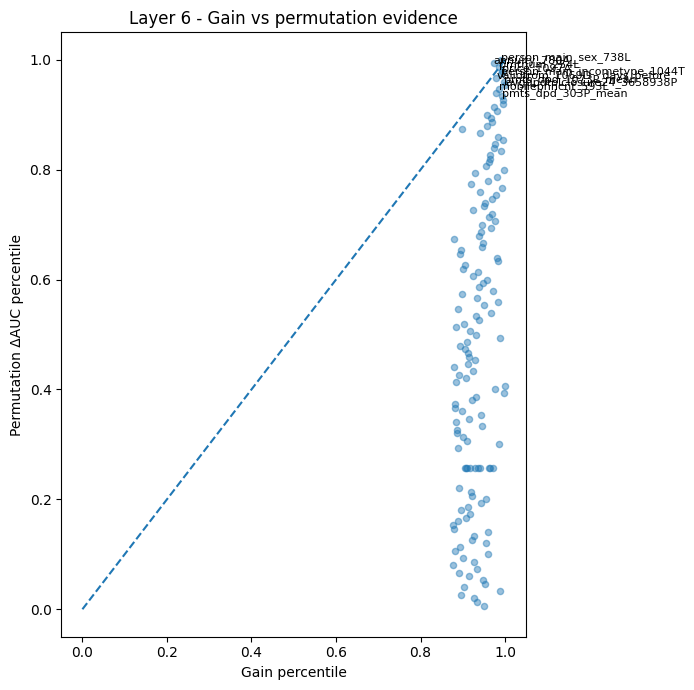

In [ ]:
# ============================================================
# Evidence D — Model Contribution checkpoint + diagnostics
# Legacy filename layer6_* is retained for downstream compatibility.
# ============================================================

model_evidence.to_csv(
    REPORT_ROOT
    / "layer6_model_evidence.csv",
    index=False,
)

print(
    "Top multivariate model evidence："
)

display(
    model_evidence[
        [
            "feature",
            "gain_importance",
            "split_importance",
            "gain_percentile",
            "permutation_delta_auc",
            "permutation_sd",
            "permutation_percentile",
            "model_score",
        ]
    ]
    .head(25)
)

plot_data = (
    model_evidence
    .dropna(
        subset=[
            "gain_percentile",
            "permutation_percentile",
        ]
    )
    .copy()
)

plt.figure(
    figsize=(7, 7)
)

plt.scatter(
    plot_data[
        "gain_percentile"
    ],
    plot_data[
        "permutation_percentile"
    ],
    alpha=0.45,
    s=20,
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

annotate_rows = (
    plot_data
    .sort_values(
        "model_score",
        ascending=False,
    )
    .head(10)
)

for row in (
    annotate_rows
    .itertuples(
        index=False
    )
):

    plt.annotate(
        row.feature[:28],
        (
            row.gain_percentile,
            row.permutation_percentile,
        ),
        fontsize=8,
    )

plt.xlabel(
    "Gain percentile"
)

plt.ylabel(
    "Permutation ΔAUC percentile"
)

plt.title(
    "Layer 6 - Gain vs permutation evidence"
)

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT
    / "layer6_gain_vs_permutation_percentile.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

## 7. Evidence E — Interaction Clues & Rescue Candidates

这一模块问：

> **有没有 feature 单独看一般，但和其他 feature 组合以后才有价值？**

如果只做单变量 ranking，这类 feature 很容易过早被压到后面。

因此这里使用 LightGBM tree paths 提供 interaction clue，并借鉴 weak-heredity 的思想：

```text
Strong Anchor
+
Weak Candidate
+
频繁出现在相同 tree path
        ↓
值得保护 / 审查
```

注意：

`interaction_rescue_candidate=True`

只表示：

> **避免因为 main effect 弱就立即忽略。**

它不等于已经证明存在统计学 interaction。

### 为什么不计算所有 feature pairs 的 H-statistic？

1,209 个 features 两两组合会产生非常大的 pair space。

如果所有 pair 都做 expensive interaction evaluation，计算成本会迅速压过真正的 Feature Selection search。

因此这里先用 tree-path clues 缩小候选范围，再把真正的 subset-level判断留到 Notebook 10 的 wrapper search / local repair。

这部分减少成本针对的是：

> **interaction pair explosion。**

但保留 Interaction Evidence 本身又是必要成本，因为完全不看 interaction 会让固定的 univariate ranking 产生系统性盲点。

### Sensitivity 副线

Strong Anchor / Weak Candidate threshold 会受到 reference relevance / model score 定义影响。

因此最重要的是保存 raw interaction quantities，例如：

- shared path count；
- anchor relationships；
- pair evidence。

标签可以在后面根据 ranking definition 重新解释。

这样以后调整 Relevance definition 时，不需要重新训练所有 trees 才能重新生成 rescue logic。


In [ ]:
def collect_tree_path_pairs(
    tree_structure,
):
    """统计一个 LightGBM tree 中 root-to-leaf path 的 feature pair。"""

    pair_counter = Counter()

    def walk(
        node,
        path_features,
    ):

        if "split_feature" not in node:

            unique_features = sorted(
                set(
                    path_features
                )
            )

            for pair in combinations(
                unique_features,
                2,
            ):
                pair_counter[
                    pair
                ] += 1

            return

        feature_index = int(
            node[
                "split_feature"
            ]
        )

        next_path = [
            *path_features,
            feature_index,
        ]

        walk(
            node[
                "left_child"
            ],
            next_path,
        )

        walk(
            node[
                "right_child"
            ],
            next_path,
        )

    walk(
        tree_structure,
        [],
    )

    return pair_counter


model_dump = (
    booster.dump_model()
)

feature_names = (
    model_dump[
        "feature_names"
    ]
)

interaction_counter = Counter()


for tree_info in (
    model_dump[
        "tree_info"
    ]
):

    tree_counter = (
        collect_tree_path_pairs(
            tree_info[
                "tree_structure"
            ]
        )
    )

    interaction_counter.update(
        tree_counter
    )


relevance_score_lookup = (
    relevance_evidence
    .set_index("feature")[
        "relevance_score"
    ]
    .to_dict()
)

model_score_lookup = (
    model_evidence
    .set_index("feature")[
        "model_score"
    ]
    .to_dict()
)


def is_strong_anchor(
    feature,
):
    """Relevance 或 Model Evidence 明显靠前。"""

    relevance_score = (
        relevance_score_lookup.get(
            feature,
            0.0,
        )
    )

    model_score = (
        model_score_lookup.get(
            feature,
            0.0,
        )
    )

    return (
        relevance_score
        >= STRONG_ANCHOR_SCORE
        or
        model_score
        >= STRONG_ANCHOR_SCORE
    )


def is_weak_candidate(
    feature,
):
    """单变量 relevance 较弱，可能较早进入删除候选。"""

    return (
        relevance_score_lookup.get(
            feature,
            0.0,
        )
        < WEAK_RELEVANCE_SCORE
    )


interaction_rows = []


for (
    feature_pair,
    path_count,
) in interaction_counter.items():

    feature_a = (
        feature_names[
            feature_pair[0]
        ]
    )

    feature_b = (
        feature_names[
            feature_pair[1]
        ]
    )

    anchor_a = (
        is_strong_anchor(
            feature_a
        )
    )

    anchor_b = (
        is_strong_anchor(
            feature_b
        )
    )

    weak_a = (
        is_weak_candidate(
            feature_a
        )
    )

    weak_b = (
        is_weak_candidate(
            feature_b
        )
    )

    weak_heredity_pair = (
        (
            anchor_a
            and weak_b
        )
        or
        (
            anchor_b
            and weak_a
        )
    )

    interaction_rows.append({
        "feature_a": feature_a,
        "feature_b": feature_b,
        "shared_path_count": (
            int(path_count)
        ),
        "feature_a_strong_anchor": (
            anchor_a
        ),
        "feature_b_strong_anchor": (
            anchor_b
        ),
        "feature_a_weak_candidate": (
            weak_a
        ),
        "feature_b_weak_candidate": (
            weak_b
        ),
        "weak_heredity_pair": (
            weak_heredity_pair
        ),
    })


interaction_pair_evidence = (
    pd.DataFrame(
        interaction_rows,
        columns=[
            "feature_a",
            "feature_b",
            "shared_path_count",
            "feature_a_strong_anchor",
            "feature_b_strong_anchor",
            "feature_a_weak_candidate",
            "feature_b_weak_candidate",
            "weak_heredity_pair",
        ],
    )
)


if not interaction_pair_evidence.empty:

    interaction_pair_evidence = (
        interaction_pair_evidence
        .sort_values(
            [
                "weak_heredity_pair",
                "shared_path_count",
            ],
            ascending=[
                False,
                False,
            ],
        )
        .reset_index(
            drop=True
        )
    )


weak_heredity_pairs = (
    interaction_pair_evidence
    .loc[
        interaction_pair_evidence[
            "weak_heredity_pair"
        ]
    ]
    .sort_values(
        "shared_path_count",
        ascending=False,
    )
    .head(
        INTERACTION_TOP_PAIR_LIMIT
    )
    .reset_index(drop=True)
)


interaction_feature_rows = []


for feature in candidate_features:

    if not is_weak_candidate(
        feature
    ):

        related = (
            weak_heredity_pairs
            .iloc[0:0]
        )

    else:

        related = (
            weak_heredity_pairs
            .loc[
                (
                    weak_heredity_pairs[
                        "feature_a"
                    ].eq(
                        feature
                    )
                )
                |
                (
                    weak_heredity_pairs[
                        "feature_b"
                    ].eq(
                        feature
                    )
                )
            ]
        )

    max_path_count = (
        int(
            related[
                "shared_path_count"
            ].max()
        )
        if len(
            related
        ) > 0
        else 0
    )

    anchor_features = []

    if len(related) > 0:

        for row in (
            related.itertuples(
                index=False
            )
        ):

            partner = (
                row.feature_b
                if row.feature_a
                == feature
                else row.feature_a
            )

            if is_strong_anchor(
                partner
            ):
                anchor_features.append(
                    partner
                )

    anchor_features = sorted(
        set(
            anchor_features
        )
    )

    rescue_candidate = (
        len(
            anchor_features
        ) > 0
    )

    interaction_feature_rows.append({
        "feature": feature,
        "max_shared_path_count": (
            max_path_count
        ),
        "interaction_anchor_count": (
            len(
                anchor_features
            )
        ),
        "interaction_anchor_examples": (
            "|".join(
                anchor_features[
                    :5
                ]
            )
        ),
        "interaction_rescue_candidate": (
            rescue_candidate
        ),
    })


interaction_feature_evidence = (
    pd.DataFrame(
        interaction_feature_rows
    )
)


display(
    weak_heredity_pairs.head(
        30
    )
)

display(
    interaction_feature_evidence
    .loc[
        interaction_feature_evidence[
            "interaction_rescue_candidate"
        ]
    ]
    .sort_values(
        "max_shared_path_count",
        ascending=False,
    )
    .head(30)
)

,feature_a,feature_b,shared_path_count,feature_a_strong_anchor,feature_b_strong_anchor,feature_a_weak_candidate,feature_b_weak_candidate,weak_heredity_pair
0,annuity_780A,previouscontdistrict_112M,581,True,True,True,False,True
1,annuity_780A,person_main_empladdr_district_926M,412,True,True,True,False,True
2,annuity_780A,taxa_top_employer_code,386,True,True,True,False,True
3,annuity_780A,mobilephncnt_593L,212,True,True,True,False,True
4,annuity_780A,residualamount_856A_mean,179,True,True,True,False,True
5,annuity_780A,pmtaverage_3A,161,True,True,True,False,True
6,annuity_780A,pmtnum_254L,160,True,True,True,False,True
7,applicationscnt_867L,previouscontdistrict_112M,159,False,True,True,False,True
8,annuity_780A,person_main_age_years,156,True,True,True,False,True
9,annuity_780A,lastrejectcommoditycat_161M,154,True,True,True,False,True


,feature,max_shared_path_count,interaction_anchor_count,interaction_anchor_examples,interaction_rescue_candidate
2,annuity_780A,581,59,annuity_853A_mean|classificationofcontr_13M_nu...,True
9,applicationscnt_867L,159,22,annuity_780A|clientscnt12m_3712952L|currdebt_9...,True
574,numberofoutstandinstls_59L_sum,115,8,annuity_780A|mobilephncnt_593L|person_main_emp...,True
1170,dtlastpmt_581D_max__days_before_decision,114,17,annuity_780A|credamount_590A_min|credlmt_230A_...,True
1172,dtlastpmtallstes_3545839D_max__days_before_dec...,109,8,annuity_780A|dateofcredstart_739D_min__days_be...,True
653,collater_valueofguarantee_1124L_sum,88,16,annuity_780A|birthdate_574D__days_before_decis...,True
577,dpdmaxdatemonth_89T_mean,84,7,days30_165L|person_main_education_927M|person_...,True
606,credlmt_230A_sum,81,14,annuity_780A|clientscnt12m_3712952L|dateofcred...,True
858,deposit_amount_mean,77,9,credtype_587L_REL_pct|familystate_726L_MARRIED...,True
136,totaldebt_9A,74,10,birthdate_574D__days_before_decision|credtype_...,True


In [ ]:
# ============================================================
# Evidence E — Interaction checkpoint + diagnostics
# Legacy filename layer7_* is retained for downstream compatibility.
# ============================================================

interaction_pair_evidence.to_csv(
    REPORT_ROOT
    / "layer7_interaction_pair_evidence.csv",
    index=False,
)

interaction_feature_evidence.to_csv(
    REPORT_ROOT
    / "layer7_interaction_feature_evidence.csv",
    index=False,
)

interaction_summary = pd.DataFrame([
    {
        "strong_anchors": int(
            sum(
                is_strong_anchor(
                    feature
                )
                for feature
                in candidate_features
            )
        ),
        "weak_candidates": int(
            sum(
                is_weak_candidate(
                    feature
                )
                for feature
                in candidate_features
            )
        ),
        "weak_heredity_pairs": int(
            len(
                weak_heredity_pairs
            )
        ),
        "rescued_features": int(
            interaction_feature_evidence[
                "interaction_rescue_candidate"
            ].sum()
        ),
    }
])

print(
    "Interaction rescue summary："
)

display(
    interaction_summary
)

print(
    "Top rescue candidates："
)

display(
    interaction_feature_evidence
    .loc[
        interaction_feature_evidence[
            "interaction_rescue_candidate"
        ]
    ]
    .sort_values(
        "max_shared_path_count",
        ascending=False,
    )
    .head(25)
)

Interaction rescue summary：


,strong_anchors,weak_candidates,weak_heredity_pairs,rescued_features
0,190,390,300,44


Top rescue candidates：


,feature,max_shared_path_count,interaction_anchor_count,interaction_anchor_examples,interaction_rescue_candidate
2,annuity_780A,581,59,annuity_853A_mean|classificationofcontr_13M_nu...,True
9,applicationscnt_867L,159,22,annuity_780A|clientscnt12m_3712952L|currdebt_9...,True
574,numberofoutstandinstls_59L_sum,115,8,annuity_780A|mobilephncnt_593L|person_main_emp...,True
1170,dtlastpmt_581D_max__days_before_decision,114,17,annuity_780A|credamount_590A_min|credlmt_230A_...,True
1172,dtlastpmtallstes_3545839D_max__days_before_dec...,109,8,annuity_780A|dateofcredstart_739D_min__days_be...,True
653,collater_valueofguarantee_1124L_sum,88,16,annuity_780A|birthdate_574D__days_before_decis...,True
577,dpdmaxdatemonth_89T_mean,84,7,days30_165L|person_main_education_927M|person_...,True
606,credlmt_230A_sum,81,14,annuity_780A|clientscnt12m_3712952L|dateofcred...,True
858,deposit_amount_mean,77,9,credtype_587L_REL_pct|familystate_726L_MARRIED...,True
136,totaldebt_9A,74,10,birthdate_574D__days_before_decision|credtype_...,True


## 8. Evidence F — Temporal Reliability

前面的 Evidence 主要回答：

> feature 现在有没有价值？

这一模块再问：

> **这种 X → target 的关系经过时间以后还能不能保持？**

这不是简单的 Distribution Drift 检查。

一个 feature 的人口分布可以变化，但风险排序仍然稳定；反过来，feature 分布变化不大，X → Y 的关系也可能发生变化。

因此这里主要保存：

- fixed-group WOE profile；
- IV over time；
- reference-WOE Gini；
- Gini slope；
- minimum temporal Gini；
- WOE profile correlation；
- sign-flip share。

### 为什么 grouping rules 必须固定？

如果每个 period 都重新分 bins，那么：

```text
P0 的 High
```

和：

```text
P4 的 High
```

可能已经不是同一群人。

那就无法判断 relationship 有没有改变。

所以 reference period 先学习固定 grouping，后面的 periods 都使用相同规则。

### 为什么这里值得付出额外计算成本？

如果完全只看当前平均预测力，Notebook 9 / 10 可能选择一个在历史 Train 内很强、但越靠近未来越衰退的 subset。

Temporal Evidence 的成本是在防止：

> **把短期强度误认为可带到未来的稳定预测价值。**

因此它属于必要成本。

### 为什么又不把所有 temporal metric 合成一个权重分数？

不同 temporal diagnostics 描述不同失败模式，例如：

- slope 持续下降；
- 某些 bins risk sign flip；
- profile correlation 下降。

Notebook 8 保存 raw metrics 和 review label，但不把这些风险压成唯一 FinalScore。

真正的 subset-level temporal robustness 仍交给 Notebook 10 的 F1–F4 evaluation。

### Sensitivity 副线

Temporal threshold 首先是 review / warning rule。

只要 raw continuous metrics 已保存，就没有必要在 NB8 里为大量 threshold 重跑昂贵 temporal calculation。


In [ ]:
# Temporal Stability 不再保存 5 份宽表。
# 这里只抽 P0 sample 学固定 grouping rules。

reference_name = (
    TEMPORAL_PERIODS[0][0]
)

reference_week_start = (
    TEMPORAL_PERIODS[0][1]
)

reference_week_end = (
    TEMPORAL_PERIODS[0][2]
)


temporal_rule_positions = (
    make_stratified_positions(
        train_meta,
        TEMPORAL_RULE_SAMPLE_SIZE,
        RANDOM_SEED + 50,
        week_start=(
            reference_week_start
        ),
        week_end=(
            reference_week_end
        ),
    )
)


temporal_group_rules = {}


for start in range(
    0,
    len(candidate_features),
    IV_FEATURE_BATCH,
):

    batch_features = (
        candidate_features[
            start:
            start
            + IV_FEATURE_BATCH
        ]
    )

    sample_frame = (
        read_sampled_columns(
            batch_features,
            temporal_rule_positions,
        )
    )

    for feature in batch_features:

        temporal_group_rules[
            feature
        ] = learn_group_rule(
            sample_frame[
                feature
            ],
            dtype_family=(
                dtype_family_lookup[
                    feature
                ]
            ),
            max_numeric_bins=(
                IV_NUMERIC_BINS
            ),
            max_categories=(
                IV_MAX_CATEGORIES
            ),
        )

    del sample_frame
    gc.collect()

    print(
        "Temporal reference rules：",
        min(
            start
            + IV_FEATURE_BATCH,
            len(candidate_features),
        ),
        "/",
        len(candidate_features),
    )

Temporal reference rules： 24 / 1209
Temporal reference rules： 48 / 1209
Temporal reference rules： 72 / 1209
Temporal reference rules： 96 / 1209
Temporal reference rules： 120 / 1209
Temporal reference rules： 144 / 1209
Temporal reference rules： 168 / 1209
Temporal reference rules： 192 / 1209
Temporal reference rules： 216 / 1209
Temporal reference rules： 240 / 1209
Temporal reference rules： 264 / 1209
Temporal reference rules： 288 / 1209
Temporal reference rules： 312 / 1209
Temporal reference rules： 336 / 1209
Temporal reference rules： 360 / 1209
Temporal reference rules： 384 / 1209
Temporal reference rules： 408 / 1209
Temporal reference rules： 432 / 1209
Temporal reference rules： 456 / 1209
Temporal reference rules： 480 / 1209
Temporal reference rules： 504 / 1209
Temporal reference rules： 528 / 1209
Temporal reference rules： 552 / 1209
Temporal reference rules： 576 / 1209
Temporal reference rules： 600 / 1209
Temporal reference rules： 624 / 1209
Temporal reference rules： 648 / 1209
Tempo

In [ ]:
def profile_comparison(
    reference_table,
    current_table,
):
    """比较两个时间段 WOE profile 的方向与形状。"""

    merged = (
        reference_table[
            [
                "group",
                "woe",
            ]
        ]
        .rename(
            columns={
                "woe": (
                    "woe_reference"
                )
            }
        )
        .merge(
            current_table[
                [
                    "group",
                    "woe",
                ]
            ].rename(
                columns={
                    "woe": (
                        "woe_current"
                    )
                }
            ),
            on="group",
            how="outer",
        )
        .fillna(0.0)
    )

    if len(merged) >= 2:

        profile_corr = (
            merged[
                [
                    "woe_reference",
                    "woe_current",
                ]
            ]
            .corr(
                method="spearman"
            )
            .iloc[
                0,
                1,
            ]
        )

    else:
        profile_corr = np.nan

    material_reference = (
        merged[
            "woe_reference"
        ].abs()
        >= WOE_SIGN_EPS
    )

    if material_reference.any():

        sign_flip = (
            np.sign(
                merged.loc[
                    material_reference,
                    "woe_reference",
                ]
            )
            !=
            np.sign(
                merged.loc[
                    material_reference,
                    "woe_current",
                ]
            )
        )

        sign_flip_share = float(
            sign_flip.mean()
        )

    else:
        sign_flip_share = np.nan

    return (
        (
            float(
                profile_corr
            )
            if pd.notna(
                profile_corr
            )
            else np.nan
        ),
        sign_flip_share,
    )


def auc_from_group_counts(
    count_table,
    score_map,
):
    """
    不保存 row-level prediction，
    直接由每个 group 的 Good / Bad counts
    和 reference risk score 精确计算 AUC。
    """

    if count_table.empty:
        return np.nan

    table = (
        count_table[
            [
                "group",
                "good_count",
                "bad_count",
            ]
        ]
        .copy()
    )

    table[
        "risk_score"
    ] = (
        table[
            "group"
        ]
        .map(
            score_map
        )
        .fillna(0.0)
    )

    table = (
        table
        .groupby(
            "risk_score",
            as_index=False,
        )[
            [
                "good_count",
                "bad_count",
            ]
        ]
        .sum()
        .sort_values(
            "risk_score"
        )
    )

    total_good = float(
        table[
            "good_count"
        ].sum()
    )

    total_bad = float(
        table[
            "bad_count"
        ].sum()
    )

    if (
        total_good <= 0
        or
        total_bad <= 0
    ):
        return np.nan

    cumulative_good = 0.0
    favorable_pairs = 0.0

    for row in (
        table.itertuples(
            index=False
        )
    ):

        good = float(
            row.good_count
        )

        bad = float(
            row.bad_count
        )

        favorable_pairs += (
            bad
            * (
                cumulative_good
                + 0.5 * good
            )
        )

        cumulative_good += good

    return (
        favorable_pairs
        / (
            total_good
            * total_bad
        )
    )


def period_name_from_weeks(
    weeks,
):
    """把一个 row group 的 WEEK_NUM 映射到 P0–P4。"""

    result = np.full(
        len(weeks),
        "",
        dtype=object,
    )

    for (
        period_name,
        week_start,
        week_end,
    ) in TEMPORAL_PERIODS:

        mask = (
            (weeks >= week_start)
            &
            (weeks <= week_end)
        )

        result[
            mask
        ] = period_name

    return result

In [ ]:
temporal_summary_rows = []
temporal_detail_rows = []


for start in range(
    0,
    len(candidate_features),
    IV_FEATURE_BATCH,
):

    batch_features = (
        candidate_features[
            start:
            start
            + IV_FEATURE_BATCH
        ]
    )

    accumulators = {
        feature: {
            period_name: {}
            for (
                period_name,
                _,
                _,
            ) in TEMPORAL_PERIODS
        }
        for feature in batch_features
    }


    for row_group_id in range(
        train_parquet.num_row_groups
    ):

        frame = (
            train_parquet
            .read_row_group(
                row_group_id,
                columns=[
                    WEEK_COL,
                    TARGET_COL,
                    *batch_features,
                ],
                use_threads=True,
            )
            .to_pandas()
        )

        weeks = (
            frame[
                WEEK_COL
            ]
            .to_numpy()
        )

        period_labels = (
            period_name_from_weeks(
                weeks
            )
        )

        for (
            period_name,
            _,
            _,
        ) in TEMPORAL_PERIODS:

            period_mask = (
                period_labels
                == period_name
            )

            if not np.any(
                period_mask
            ):
                continue

            period_target = (
                frame.loc[
                    period_mask,
                    TARGET_COL,
                ]
            )

            for feature in (
                batch_features
            ):

                groups = (
                    apply_group_rule(
                        frame.loc[
                            period_mask,
                            feature,
                        ],
                        temporal_group_rules[
                            feature
                        ],
                    )
                )

                update_binary_count_dict(
                    accumulators[
                        feature
                    ][
                        period_name
                    ],
                    groups,
                    period_target,
                )

        del frame
        gc.collect()


    for feature in batch_features:

        reference_counts = (
            count_dict_to_woe_table(
                accumulators[
                    feature
                ][
                    reference_name
                ]
            )
        )

        reference_woe_map = (
            reference_counts
            .set_index(
                "group"
            )[
                "woe"
            ]
            .to_dict()
        )

        reference_risk_map = {
            group: (
                -1.0
                * float(woe)
            )
            for group, woe
            in reference_woe_map.items()
        }

        period_iv_values = []
        period_gini_values = []
        profile_corr_values = []
        sign_flip_values = []


        for (
            period_name,
            _,
            _,
        ) in TEMPORAL_PERIODS:

            current_table = (
                count_dict_to_woe_table(
                    accumulators[
                        feature
                    ][
                        period_name
                    ]
                )
            )

            current_iv = float(
                current_table[
                    "iv_component"
                ].sum()
            )

            current_auc = (
                auc_from_group_counts(
                    current_table,
                    reference_risk_map,
                )
            )

            period_gini = (
                (
                    2.0
                    * current_auc
                    - 1.0
                )
                if pd.notna(
                    current_auc
                )
                else np.nan
            )

            (
                profile_corr,
                sign_flip_share,
            ) = profile_comparison(
                reference_counts,
                current_table,
            )

            period_iv_values.append(
                current_iv
            )

            period_gini_values.append(
                period_gini
            )

            if period_name != (
                reference_name
            ):

                profile_corr_values.append(
                    profile_corr
                )

                sign_flip_values.append(
                    sign_flip_share
                )

            temporal_detail_rows.append({
                "feature": feature,
                "period": (
                    period_name
                ),
                "iv": current_iv,
                "reference_woe_gini": (
                    period_gini
                ),
                "woe_profile_corr": (
                    profile_corr
                ),
                "woe_sign_flip_share": (
                    sign_flip_share
                ),
            })


        valid_gini = np.array(
            [
                value
                for value
                in period_gini_values
                if pd.notna(
                    value
                )
            ],
            dtype=float,
        )

        if len(valid_gini) >= 2:

            gini_slope = float(
                np.polyfit(
                    np.arange(
                        len(
                            valid_gini
                        )
                    ),
                    valid_gini,
                    deg=1,
                )[0]
            )

        else:
            gini_slope = np.nan


        iv_array = np.array(
            period_iv_values,
            dtype=float,
        )

        iv_mean = float(
            np.nanmean(
                iv_array
            )
        )

        iv_cv = (
            float(
                np.nanstd(
                    iv_array,
                    ddof=1,
                )
                / abs(
                    iv_mean
                )
            )
            if (
                len(iv_array) > 1
                and
                abs(iv_mean)
                > 1e-12
            )
            else np.nan
        )


        min_gini = (
            float(
                np.nanmin(
                    valid_gini
                )
            )
            if len(
                valid_gini
            ) > 0
            else np.nan
        )


        latest_profile_corr = (
            profile_corr_values[
                -1
            ]
            if len(
                profile_corr_values
            ) > 0
            else np.nan
        )


        max_sign_flip_share = (
            float(
                np.nanmax(
                    sign_flip_values
                )
            )
            if (
                len(
                    sign_flip_values
                ) > 0
                and
                not np.all(
                    pd.isna(
                        sign_flip_values
                    )
                )
            )
            else np.nan
        )


        # 这些仍然只是 review labels。
        if len(valid_gini) < 3:

            temporal_label = (
                "INSUFFICIENT_HISTORY"
            )

        elif (
            pd.notna(
                latest_profile_corr
            )
            and
            latest_profile_corr < 0
            and
            pd.notna(
                max_sign_flip_share
            )
            and
            max_sign_flip_share
            >= 0.50
        ):

            temporal_label = (
                "DIRECTION_REVERSAL_REVIEW"
            )

        elif (
            pd.notna(
                min_gini
            )
            and
            min_gini < 0
        ):

            temporal_label = (
                "DRIFT_REVIEW"
            )

        else:

            temporal_label = (
                "STABLE_CANDIDATE"
            )


        temporal_summary_rows.append({
            "feature": feature,
            "temporal_iv_mean": (
                iv_mean
            ),
            "temporal_iv_cv": (
                iv_cv
            ),
            "temporal_gini_min": (
                min_gini
            ),
            "temporal_gini_slope": (
                gini_slope
            ),
            "latest_woe_profile_corr": (
                latest_profile_corr
            ),
            "max_woe_sign_flip_share": (
                max_sign_flip_share
            ),
            "temporal_label": (
                temporal_label
            ),
        })


    del accumulators
    gc.collect()

    print(
        "Full-data temporal evidence：",
        min(
            start
            + IV_FEATURE_BATCH,
            len(candidate_features),
        ),
        "/",
        len(candidate_features),
    )


temporal_summary = (
    pd.DataFrame(
        temporal_summary_rows
    )
)

temporal_detail = (
    pd.DataFrame(
        temporal_detail_rows
    )
)


display(
    temporal_summary[
        "temporal_label"
    ]
    .value_counts(
        dropna=False
    )
)

display(
    temporal_summary
    .sort_values(
        [
            "max_woe_sign_flip_share",
            "temporal_gini_min",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .head(30)
)

Full-data temporal evidence： 24 / 1209
Full-data temporal evidence： 48 / 1209
Full-data temporal evidence： 72 / 1209
Full-data temporal evidence： 96 / 1209
Full-data temporal evidence： 120 / 1209
Full-data temporal evidence： 144 / 1209
Full-data temporal evidence： 168 / 1209
Full-data temporal evidence： 192 / 1209
Full-data temporal evidence： 216 / 1209
Full-data temporal evidence： 240 / 1209
Full-data temporal evidence： 264 / 1209
Full-data temporal evidence： 288 / 1209
Full-data temporal evidence： 312 / 1209
Full-data temporal evidence： 336 / 1209
Full-data temporal evidence： 360 / 1209
Full-data temporal evidence： 384 / 1209
Full-data temporal evidence： 408 / 1209
Full-data temporal evidence： 432 / 1209
Full-data temporal evidence： 456 / 1209
Full-data temporal evidence： 480 / 1209
Full-data temporal evidence： 504 / 1209
Full-data temporal evidence： 528 / 1209
Full-data temporal evidence： 552 / 1209
Full-data temporal evidence： 576 / 1209
Full-data temporal evidence： 600 / 1209
Full

temporal_label
STABLE_CANDIDATE             996
DIRECTION_REVERSAL_REVIEW    164
DRIFT_REVIEW                  49
Name: count, dtype: int64

,feature,temporal_iv_mean,temporal_iv_cv,temporal_gini_min,temporal_gini_slope,latest_woe_profile_corr,max_woe_sign_flip_share,temporal_label
19,cardtype_51L,0.006449,1.117977,-0.042152,-0.009224,-1.000000,1.0,DIRECTION_REVERSAL_REVIEW
1139,taxc_latest_recency_days,0.006801,1.353251,-0.036157,-0.007173,NaN,1.0,DRIFT_REVIEW
633,collater_typofvalofguarant_298M_nunique,0.003849,0.608005,-0.030162,-0.015907,0.200000,1.0,DRIFT_REVIEW
478,numberofinstls_320L_sum,0.011126,0.458545,-0.021455,-0.020584,-0.571429,1.0,DIRECTION_REVERSAL_REVIEW
622,nominalrate_498L_sum,0.004192,0.453369,-0.014818,-0.011098,-0.800000,1.0,DIRECTION_REVERSAL_REVIEW
496,totaloutstanddebtvalue_668A_max,0.004887,1.105472,-0.011329,-0.014791,-1.000000,1.0,DIRECTION_REVERSAL_REVIEW
497,totaloutstanddebtvalue_668A_mean,0.004887,1.105472,-0.011329,-0.014791,-1.000000,1.0,DIRECTION_REVERSAL_REVIEW
628,totaldebtoverduevalue_718A_max,0.004887,1.105472,-0.011329,-0.014791,-1.000000,1.0,DIRECTION_REVERSAL_REVIEW
629,totaldebtoverduevalue_718A_mean,0.004887,1.105472,-0.011329,-0.014791,-1.000000,1.0,DIRECTION_REVERSAL_REVIEW
556,periodicityofpmts_837L_max,0.002626,1.177385,-0.011297,-0.014990,-0.500000,1.0,DIRECTION_REVERSAL_REVIEW


Temporal label counts：


,temporal_label,feature_count
0,STABLE_CANDIDATE,996
1,DIRECTION_REVERSAL_REVIEW,164
2,DRIFT_REVIEW,49


Temporal review watchlist：


,feature,temporal_iv_mean,temporal_iv_cv,temporal_gini_min,temporal_gini_slope,latest_woe_profile_corr,max_woe_sign_flip_share,temporal_label
19,cardtype_51L,0.006449,1.117977,-0.042152,-0.009224,-1.000000,1.0,DIRECTION_REVERSAL_REVIEW
1139,taxc_latest_recency_days,0.006801,1.353251,-0.036157,-0.007173,NaN,1.0,DRIFT_REVIEW
633,collater_typofvalofguarant_298M_nunique,0.003849,0.608005,-0.030162,-0.015907,0.200000,1.0,DRIFT_REVIEW
478,numberofinstls_320L_sum,0.011126,0.458545,-0.021455,-0.020584,-0.571429,1.0,DIRECTION_REVERSAL_REVIEW
622,nominalrate_498L_sum,0.004192,0.453369,-0.014818,-0.011098,-0.800000,1.0,DIRECTION_REVERSAL_REVIEW
496,totaloutstanddebtvalue_668A_max,0.004887,1.105472,-0.011329,-0.014791,-1.000000,1.0,DIRECTION_REVERSAL_REVIEW
497,totaloutstanddebtvalue_668A_mean,0.004887,1.105472,-0.011329,-0.014791,-1.000000,1.0,DIRECTION_REVERSAL_REVIEW
628,totaldebtoverduevalue_718A_max,0.004887,1.105472,-0.011329,-0.014791,-1.000000,1.0,DIRECTION_REVERSAL_REVIEW
629,totaldebtoverduevalue_718A_mean,0.004887,1.105472,-0.011329,-0.014791,-1.000000,1.0,DIRECTION_REVERSAL_REVIEW
556,periodicityofpmts_837L_max,0.002626,1.177385,-0.011297,-0.014990,-0.500000,1.0,DIRECTION_REVERSAL_REVIEW


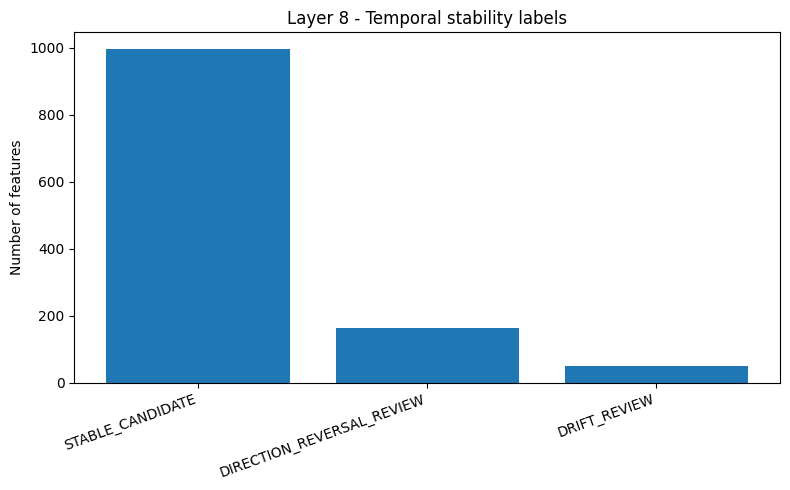

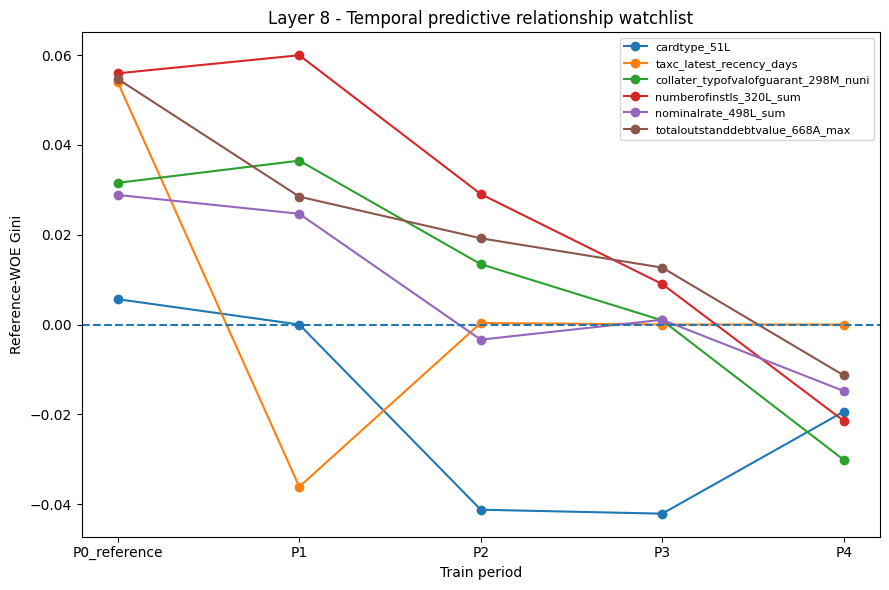

In [ ]:
# ============================================================
# Evidence F — Temporal Reliability checkpoint + diagnostics
# Legacy filename layer8_* is retained for downstream compatibility.
# ============================================================

temporal_summary.to_csv(
    REPORT_ROOT
    / "layer8_temporal_summary.csv",
    index=False,
)

temporal_detail.to_csv(
    REPORT_ROOT
    / "layer8_temporal_detail.csv",
    index=False,
)

temporal_label_summary = (
    temporal_summary[
        "temporal_label"
    ]
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "temporal_label"
    )
    .reset_index(
        name="feature_count"
    )
)

print(
    "Temporal label counts："
)

display(
    temporal_label_summary
)

print(
    "Temporal review watchlist："
)

display(
    temporal_summary
    .sort_values(
        [
            "max_woe_sign_flip_share",
            "temporal_gini_min",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .head(25)
)

plt.figure(
    figsize=(8, 5)
)

plt.bar(
    temporal_label_summary[
        "temporal_label"
    ],
    temporal_label_summary[
        "feature_count"
    ],
)

plt.ylabel(
    "Number of features"
)

plt.title(
    "Layer 8 - Temporal stability labels"
)

plt.xticks(
    rotation=20,
    ha="right",
)

plt.tight_layout()

plt.savefig(
    FIGURE_ROOT
    / "layer8_temporal_label_counts.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

# 选择最值得审查的一小批 feature，画 reference-WOE Gini 的时间轨迹。
watch_features = (
    temporal_summary
    .assign(
        review_priority=(
            temporal_summary[
                "temporal_label"
            ].ne(
                "STABLE_CANDIDATE"
            )
        ).astype(int)
    )
    .sort_values(
        [
            "review_priority",
            "max_woe_sign_flip_share",
            "temporal_gini_min",
        ],
        ascending=[
            False,
            False,
            True,
        ],
    )
    .head(6)[
        "feature"
    ]
    .tolist()
)

period_order = [
    period_name
    for (
        period_name,
        _,
        _,
    ) in TEMPORAL_PERIODS
]

if watch_features:

    trajectory = (
        temporal_detail
        .loc[
            temporal_detail[
                "feature"
            ].isin(
                watch_features
            )
        ]
        .copy()
    )

    trajectory[
        "period"
    ] = pd.Categorical(
        trajectory[
            "period"
        ],
        categories=(
            period_order
        ),
        ordered=True,
    )

    trajectory = (
        trajectory
        .sort_values(
            [
                "feature",
                "period",
            ]
        )
    )

    plt.figure(
        figsize=(9, 6)
    )

    for feature in (
        watch_features
    ):

        feature_rows = (
            trajectory
            .loc[
                trajectory[
                    "feature"
                ].eq(
                    feature
                )
            ]
        )

        plt.plot(
            feature_rows[
                "period"
            ].astype(str),
            feature_rows[
                "reference_woe_gini"
            ],
            marker="o",
            label=feature[:36],
        )

    plt.axhline(
        0.0,
        linestyle="--",
    )

    plt.xlabel(
        "Train period"
    )

    plt.ylabel(
        "Reference-WOE Gini"
    )

    plt.title(
        "Layer 8 - Temporal predictive relationship watchlist"
    )

    plt.legend(
        fontsize=8,
        loc="best",
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_ROOT
        / "layer8_temporal_gini_watchlist.png",
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()

## 9. Atomic Feature Evidence Profile：平行证据在这里汇合

前面不是：

```text
Coverage
↓
Relevance
↓
Redundancy
↓
Model
↓
Interaction
↓
Temporal
```

这种不可逆漏斗。

更准确的是：

```text
                    Feature X
                        │
        ┌───────────────┼────────────────┐
        ↓               ↓                ↓
     Coverage        Relevance       Redundancy
        ↓               ↓                ↓
        ├──────── Model Contribution ─────┤
        ↓               ↓                ↓
    Interaction     Temporal Reliability
        └───────────────┬────────────────┘
                        ↓
              Atomic Evidence Profile
```

同一个 feature 可以同时出现：

```text
Relevance       高
Redundancy      高
Gain            低
Interaction     强
Temporal        不稳定
```

这些不是逻辑矛盾，而是在回答不同问题。

因此这里合并 evidence table 的目的不是做一个“大一统 FinalScore”，而是让 Notebook 9 能够看到完整冲突结构。

### 两条线在这里第一次会合

主线得到：

> **Search Preparation 完成：每个 feature 已经有一份多维 Evidence Profile。**

副线得到：

> **哪些 Evidence 依赖 sample、threshold、category cap 或 reference composite，需要在进入昂贵 subset search 前做稳定性检查。**

这里保留 `relevance_score` / `model_score` 作为 reference diagnostics，但真正重要的是 atomic columns 本身，例如：

- `iv_percentile`
- `mi_percentile`
- `gain_percentile`
- `permutation_percentile`
- redundancy relations
- interaction raw evidence
- temporal continuous metrics

这些才是 Notebook 9 构造不同 Ranking Paths 的基础。


In [ ]:
feature_evidence = (
    candidate_catalog[
        [
            "column",
            "dtype",
            "dtype_family",
            "role",
            "origin",
        ]
    ]
    .rename(
        columns={
            "column": "feature"
        }
    )
    .merge(
        coverage_evidence,
        on="feature",
        how="left",
    )
    .merge(
        relevance_evidence[
            [
                "feature",
                "iv",
                "mi",
                "iv_percentile",
                "mi_percentile",
                "relevance_score",
            ]
        ],
        on="feature",
        how="left",
    )
    .merge(
        numeric_redundancy,
        on="feature",
        how="left",
    )
    .merge(
        model_evidence[
            [
                "feature",
                "gain_importance",
                "split_importance",
                "gain_percentile",
                "permutation_delta_auc",
                "permutation_sd",
                "permutation_percentile",
                "model_score",
            ]
        ],
        on="feature",
        how="left",
    )
    .merge(
        interaction_feature_evidence,
        on="feature",
        how="left",
    )
    .merge(
        temporal_summary,
        on="feature",
        how="left",
    )
)


feature_evidence[
    "numeric_redundancy_group"
] = (
    feature_evidence[
        "numeric_redundancy_group"
    ]
    .astype("Int64")
)

feature_evidence[
    "numeric_cluster_size"
] = (
    feature_evidence[
        "numeric_cluster_size"
    ]
    .fillna(1)
    .astype(int)
)

feature_evidence[
    "interaction_rescue_candidate"
] = (
    feature_evidence[
        "interaction_rescue_candidate"
    ]
    .fillna(False)
)


feature_evidence = (
    feature_evidence
    .sort_values(
        [
            "relevance_score",
            "model_score",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)


display(
    feature_evidence.head(30)
)

,feature,dtype,dtype_family,role,origin,missing_rate,valid_count,sample_unique_count,sample_percent_unique,sample_dominant_share,...,interaction_anchor_count,interaction_anchor_examples,interaction_rescue_candidate,temporal_iv_mean,temporal_iv_cv,temporal_gini_min,temporal_gini_slope,latest_woe_profile_corr,max_woe_sign_flip_share,temporal_label
0,datelastinstal40dpd_247D__days_before_decision,int32,numeric,model_feature,derived_from_date,0.922455,99419,4433,1.7732,0.922612,...,0,,False,0.167447,0.175740,0.094377,0.008819,0.845455,0.000000,STABLE_CANDIDATE
1,pmtcount_693L,double,numeric,model_feature,original,0.885806,146406,30,0.0120,0.885724,...,0,,False,0.022791,1.366895,0.000000,-0.025241,NaN,1.000000,STABLE_CANDIDATE
2,overdueamountmax2date_1142D_min__days_before_d...,int32,numeric,model_feature,derived_from_date,0.663637,431245,3130,1.2520,0.663164,...,0,,False,0.166548,0.142000,0.169292,0.008758,0.954545,0.100000,STABLE_CANDIDATE
3,assignmentdate_238D__days_before_decision,int32,numeric,model_feature,derived_from_date,0.893146,136996,6821,2.7284,0.893272,...,0,,False,0.024947,1.347810,0.000000,-0.025560,NaN,1.000000,STABLE_CANDIDATE
4,numberofoverdueinstlmaxdat_641D_max__days_befo...,int32,numeric,model_feature,derived_from_date,0.666841,427137,2467,0.9868,0.666280,...,0,,False,0.197481,0.104296,0.191324,0.006493,0.954545,0.090909,STABLE_CANDIDATE
5,overdueamountmax2date_1142D_max__days_before_d...,int32,numeric,model_feature,derived_from_date,0.663637,431245,3011,1.2044,0.663164,...,0,,False,0.184443,0.127074,0.181170,0.007788,0.963636,0.090909,STABLE_CANDIDATE
6,dpdmaxdateyear_596T_max,double,numeric,model_feature,original,0.174653,1058163,6,0.0024,0.479904,...,0,,False,0.079788,0.319653,0.081090,-0.021450,-0.200000,0.500000,DIRECTION_REVERSAL_REVIEW
7,lastdelinqdate_224D__days_before_decision,int32,numeric,model_feature,derived_from_date,0.655699,441422,3099,1.2396,0.654940,...,0,,False,0.152805,0.166800,0.162264,0.008269,0.945455,0.000000,STABLE_CANDIDATE
8,dpdmaxdateyear_896T_max,double,numeric,model_feature,original,0.383288,790675,18,0.0072,0.384072,...,0,,False,0.089210,0.314322,0.102277,0.006598,1.000000,0.000000,STABLE_CANDIDATE
9,numberofoverdueinstlmaxdat_641D_min__days_befo...,int32,numeric,model_feature,derived_from_date,0.666841,427137,2551,1.0204,0.666280,...,0,,False,0.179849,0.127698,0.178068,0.004904,0.945455,0.100000,STABLE_CANDIDATE


In [ ]:
# ============================================================
# Atomic Evidence handoff for Notebook 9
# ============================================================

feature_evidence.to_csv(
    REPORT_ROOT
    / "feature_evidence_report.csv",
    index=False,
)

nb9_ready_columns = [
    "feature",
    "iv_percentile",
    "mi_percentile",
    "relevance_score",
    "gain_percentile",
    "permutation_percentile",
    "model_score",
    "numeric_redundancy_group",
    "numeric_cluster_size",
    "interaction_rescue_candidate",
    "max_shared_path_count",
    "temporal_label",
    "temporal_iv_cv",
    "temporal_gini_min",
    "temporal_gini_slope",
    "latest_woe_profile_corr",
    "max_woe_sign_flip_share",
]

nb9_ready_columns = [
    column
    for column
    in nb9_ready_columns
    if column
    in feature_evidence.columns
]

print(
    "Notebook 9 可直接读取的 atomic evidence："
)

display(
    feature_evidence[
        nb9_ready_columns
    ].head(20)
)

Notebook 9 可直接读取的 atomic evidence：


,feature,iv_percentile,mi_percentile,relevance_score,gain_percentile,permutation_percentile,model_score,numeric_redundancy_group,numeric_cluster_size,interaction_rescue_candidate,max_shared_path_count,temporal_label,temporal_iv_cv,temporal_gini_min,temporal_gini_slope,latest_woe_profile_corr,max_woe_sign_flip_share
0,datelastinstal40dpd_247D__days_before_decision,0.948718,0.848635,0.898677,0.891646,0.220000,0.555823,98,1,False,0,STABLE_CANDIDATE,0.175740,0.094377,0.008819,0.845455,0.000000
1,pmtcount_693L,0.830438,0.938792,0.884615,0.275434,NaN,0.275434,74,6,False,0,STABLE_CANDIDATE,1.366895,0.000000,-0.025241,NaN,1.000000
2,overdueamountmax2date_1142D_min__days_before_d...,0.946237,0.780811,0.863524,0.684036,NaN,0.684036,214,1,False,0,STABLE_CANDIDATE,0.142000,0.169292,0.008758,0.954545,0.100000
3,assignmentdate_238D__days_before_decision,0.849462,0.874276,0.861869,0.275434,NaN,0.275434,376,1,False,0,STABLE_CANDIDATE,1.347810,0.000000,-0.025560,NaN,1.000000
4,numberofoverdueinstlmaxdat_641D_max__days_befo...,0.962779,0.754342,0.858561,0.883375,0.340000,0.611687,212,2,False,0,STABLE_CANDIDATE,0.104296,0.191324,0.006493,0.954545,0.090909
5,overdueamountmax2date_1142D_max__days_before_d...,0.953681,0.758478,0.856079,0.964433,0.820000,0.892217,212,2,False,0,STABLE_CANDIDATE,0.127074,0.181170,0.007788,0.963636,0.090909
6,dpdmaxdateyear_596T_max,0.934657,0.770885,0.852771,0.275434,NaN,0.275434,206,4,False,0,DIRECTION_REVERSAL_REVIEW,0.319653,0.081090,-0.021450,-0.200000,0.500000
7,lastdelinqdate_224D__days_before_decision,0.941274,0.751034,0.846154,0.966088,0.893333,0.929711,99,3,False,0,STABLE_CANDIDATE,0.166800,0.162264,0.008269,0.945455,0.000000
8,dpdmaxdateyear_896T_max,0.923077,0.768404,0.845740,0.691481,NaN,0.691481,281,2,False,0,STABLE_CANDIDATE,0.314322,0.102277,0.006598,1.000000,0.000000
9,numberofoverdueinstlmaxdat_641D_min__days_befo...,0.951199,0.739454,0.845327,0.832920,NaN,0.832920,213,1,False,0,STABLE_CANDIDATE,0.127698,0.178068,0.004904,0.945455,0.100000


## 10. 输出与下游接口

Notebook 08 不直接确定最终特征子集，主要输出为 `feature_evidence_report.csv` 及各类原子证据表，包括 Coverage、IV / MI、Redundancy relations、Gain / Permutation、Interaction 和 Temporal diagnostics。

部分中间文件沿用 `layer3_...`、`layer4_...` 等历史名称，以保持 Notebook 09 的读取兼容性；这些名称不表示严格的逐层筛选。

**敏感性检查：** 附加审查聚焦可能改变候选路线的参数，例如 categorical IV grouping、ranking weights 或 redundancy boundaries；后续仅将有足够差异的路线传入成本更高的 Notebook 10。

**后续流程：** `Notebook 08 (Atomic Evidence) → Notebook 09 (Ranking Routes) → Notebook 10 (Subset Search)`。

### 方法参考
- Guyon & Elisseeff (2003), *An Introduction to Variable and Feature Selection*.
- Brown et al. (2012), *Conditional Likelihood Maximisation: A Unifying Framework for Information Theoretic Feature Selection*.
- Kohavi & John (1997), *Wrappers for Feature Subset Selection*.
- Nogueira, Sechidis & Brown (2018), *On the Stability of Feature Selection Algorithms*.

上述文献用于说明方法设计背景，不代表本项目严格复现了相应论文中的全部算法。


In [ ]:
# ------------------------------
# 1. 主 evidence table
# ------------------------------

feature_evidence.to_csv(
    REPORT_ROOT
    / "feature_evidence_report.csv",
    index=False,
)


# ------------------------------
# 2. Atomic evidence tables
# ------------------------------

coverage_evidence.to_csv(
    REPORT_ROOT
    / "layer3_coverage_evidence.csv",
    index=False,
)

relevance_evidence.to_csv(
    REPORT_ROOT
    / "layer4_relevance_evidence.csv",
    index=False,
)

model_evidence.to_csv(
    REPORT_ROOT
    / "layer6_model_evidence.csv",
    index=False,
)


# ------------------------------
# 3. Redundancy evidence
# ------------------------------

numeric_redundancy.to_csv(
    REPORT_ROOT
    / "numeric_redundancy_groups.csv",
    index=False,
)

categorical_redundancy_pairs.to_csv(
    REPORT_ROOT
    / "categorical_redundancy_pairs.csv",
    index=False,
)

mixed_redundancy_review.to_csv(
    REPORT_ROOT
    / "mixed_redundancy_review.csv",
    index=False,
)

if not redundancy_sample_audit.empty:

    redundancy_sample_audit.to_csv(
        REPORT_ROOT
        / "redundancy_sample_audit.csv",
        index=False,
    )


# ------------------------------
# 4. Relevance audit
# ------------------------------

if not mi_sample_audit.empty:

    mi_sample_audit.to_csv(
        REPORT_ROOT
        / "mi_sample_size_audit.csv",
        index=False,
    )


# ------------------------------
# 5. Interaction evidence
# ------------------------------

interaction_pair_evidence.to_csv(
    REPORT_ROOT
    / "interaction_pair_evidence.csv",
    index=False,
)

interaction_feature_evidence.to_csv(
    REPORT_ROOT
    / "interaction_feature_evidence.csv",
    index=False,
)


# ------------------------------
# 6. Temporal evidence
# ------------------------------

temporal_summary.to_csv(
    REPORT_ROOT
    / "temporal_feature_watchlist.csv",
    index=False,
)

temporal_detail.to_csv(
    REPORT_ROOT
    / "temporal_feature_detail.csv",
    index=False,
)


# ------------------------------
# 7. 配置
# ------------------------------

nb8_config = {
    "random_seed": RANDOM_SEED,
    "train_week_min": 0,
    "train_week_max": 63,
    "validation_read": False,
    "oot_read": False,
    "candidate_feature_count": (
        len(candidate_features)
    ),

    "data_strategy": (
        "full-data streaming where additive; "
        "stratified sampling only where necessary"
    ),


    "methodology_role": (
        "search preparation + atomic evidence profiling"
    ),
    "evidence_modules_are_parallel": True,
    "composite_scores_are_reference_views_only": True,
    "cost_principle": (
        "pay computation when it prevents a defined search error; "
        "remove computation that only repeats existing evidence"
    ),
    "sensitivity_audit_plan": (
        SENSITIVITY_AUDIT_PLAN
    ),


    "notebook9_reweighting": (
        "Notebook 9 may recompute evidence weights from atomic percentiles "
        "without rerunning Notebook 8"
    ),
    "relevance_components": [
        "iv_percentile",
        "mi_percentile",
    ],
    "default_relevance_weights": {
        "iv_percentile": 0.5,
        "mi_percentile": 0.5,
    },
    "model_components": [
        "gain_percentile",
        "permutation_percentile",
    ],
    "default_model_weights": {
        "gain_percentile": 0.5,
        "permutation_percentile": 0.5,
    },

    "profile_sample_size": (
        PROFILE_SAMPLE_SIZE
    ),
    "iv_rule_sample_size": (
        IV_RULE_SAMPLE_SIZE
    ),
    "iv_final_counts": (
        "full_train_streaming"
    ),

    "mi_sample_size": (
        MI_SAMPLE_SIZE
    ),
    "mi_sample_audit_run": (
        RUN_MI_SAMPLE_AUDIT
    ),
    "mi_audit_sizes": (
        MI_AUDIT_SIZES
    ),

    "redundancy_sample_size": (
        REDUNDANCY_SAMPLE_SIZE
    ),
    "redundancy_sample_audit_run": (
        RUN_REDUNDANCY_SAMPLE_AUDIT
    ),
    "redundancy_audit_size": (
        REDUNDANCY_AUDIT_SIZE
    ),

    "permutation_top_k": (
        PERMUTATION_TOP_K
    ),
    "permutation_sample_size": (
        PERMUTATION_SAMPLE_SIZE
    ),
    "permutation_repeats": (
        PERMUTATION_REPEATS
    ),

    "temporal_rule_sample_size": (
        TEMPORAL_RULE_SAMPLE_SIZE
    ),
    "temporal_final_counts": (
        "full_train_streaming"
    ),

    "high_missing_rate": (
        HIGH_MISSING_RATE
    ),
    "extreme_missing_rate": (
        EXTREME_MISSING_RATE
    ),
    "nzv_freq_ratio": (
        NZV_FREQ_RATIO
    ),
    "nzv_percent_unique": (
        NZV_PERCENT_UNIQUE
    ),

    "numeric_redundancy_rho": (
        NUMERIC_REDUNDANCY_RHO
    ),
    "categorical_redundancy_v": (
        CATEGORICAL_REDUNDANCY_V
    ),
    "mixed_eta2_review": (
        MIXED_ETA2_REVIEW
    ),

    "interaction_strong_anchor_score": (
        STRONG_ANCHOR_SCORE
    ),
    "interaction_weak_relevance_score": (
        WEAK_RELEVANCE_SCORE
    ),
    "interaction_top_pair_limit": (
        INTERACTION_TOP_PAIR_LIMIT
    ),

    "temporal_periods": (
        TEMPORAL_PERIODS
    ),

    "confirmed_exclude_features": (
        CONFIRMED_EXCLUDE_FEATURES
    ),

    "model_fit_end_week": (
        MODEL_FIT_END_WEEK
    ),
    "model_assess_start_week": (
        MODEL_ASSESS_START_WEEK
    ),

    "lgbm_streaming": True,
    "lgbm_bin_construct_sample_cnt": (
        LGBM_BIN_SAMPLE_COUNT
    ),
    "lgbm_n_estimators": 300,
    "lgbm_learning_rate": 0.05,
    "lgbm_num_leaves": 31,
    "lgbm_subsample": 0.8,
    "lgbm_subsample_freq": 1,
    "lgbm_colsample_bytree": 0.8,
    "lgbm_reg_lambda": 1.0,
}


with open(
    REPORT_ROOT
    / "nb8_feature_evidence_config.json",
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        nb8_config,
        file,
        ensure_ascii=False,
        indent=2,
    )



with open(
    REPORT_ROOT
    / "nb8_sensitivity_audit_plan.json",
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        SENSITIVITY_AUDIT_PLAN,
        file,
        ensure_ascii=False,
        indent=2,
    )


print(
    "Notebook 8 evidence 已保存到："
)

print(
    REPORT_ROOT
)

Notebook 8 evidence 已保存到：
/kaggle/working/reports/feature_evidence
